# Clusters de comportamiento de mercado

¿Cuántas maneras distintas de comportarse tiene el suelo de Bogotá, y cuáles
destacan?

**La decisión de diseño:** los grupos se forman **solo con el comportamiento de
mercado** de cada manzana —su precio, cómo se movió en diez años, qué tan
errático fue y qué dice el pronóstico—. Ubicación, morfología, estrato y uso **no
entran**. Si entraran, los grupos saldrían geográficos por construcción y decir
"este grupo está en el norte y es caro" sería circular. Fuera del agrupamiento,
esas variables pasan a ser la **validación**: si los grupos que salen del
comportamiento coinciden con zonas, edificaciones y estratos reconocibles,
capturaron algo real.

Requiere haber corrido `02_pronostico.ipynb`, que deja el pronóstico por manzana.

In [1]:
import sys
import warnings
from pathlib import Path

import geopandas as gpd
import folium
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display
from sklearn.cluster import DBSCAN, KMeans, MiniBatchKMeans
from sklearn.decomposition import PCA
from sklearn.isotonic import IsotonicRegression
from sklearn.metrics import (adjusted_rand_score, calinski_harabasz_score,
                             davies_bouldin_score, silhouette_score)
from sklearn.mixture import GaussianMixture
from sklearn.neighbors import NearestNeighbors
from sklearn.preprocessing import StandardScaler

warnings.filterwarnings("ignore")
sys.path.insert(0, str(Path.cwd().parent / "src"))
import config as C

ANIO_RECIENTE = 2023          # desde donde se mide el tramo "reciente"
K_RANGO = range(2, 13)
N_ESTABILIDAD = 15            # repeticiones del test de estabilidad
N_SUB = 6000                  # submuestra para la silueta, que es O(n^2)
K_VECINOS = 8                 # vecinos geograficos para la pureza espacial

AZUL, VERDE, NARANJA, ROJO, GRIS = "#264653", "#2a9d8f", "#f4a261", "#e76f51", "#9aa5ab"
PALETA = ["#264653", "#2a9d8f", "#e9c46a", "#f4a261", "#e76f51", "#7b2cbf",
          "#0077b6", "#06d6a0", "#bc6c25", "#8d99ae", "#d62828", "#3a5a40"]
TAM_MAPA = (5, 8)
rng = np.random.default_rng(C.SEMILLA)

def pesos(x, pos=None):
    return "%.1f M" % (x / 1e6) if x >= 1e6 else "%.0f k" % (x / 1e3)

pct = lambda g: 100 * (10 ** g - 1)

## 1. Las variables de comportamiento

Cada manzana queda descrita por su propia serie y nada más: dónde está parada
(`nivel`), hacia dónde va (`tadc_total`, `tadc_reciente`), qué tan errática es
(`volatilidad`, `salto_max`), qué tan quieta la tiene Catastro (`inercia`) y qué
dice el pronóstico (`pron_relativo`).

**De dónde salen.** La materia prima es el valor de referencia del m² que publica
Catastro cada año (`valor_referencia_serie.csv.gz`, columna `V_REF`). Si una
manzana trae varios registros en un año se toma la mediana, y solo entran las
manzanas con valor en los diez años, 2017 a 2026. Llamando $P_t$ a ese valor en el
año $t$, todo se calcula sobre su logaritmo, y el cambio de un año es

$$g_t = \log_{10} P_t - \log_{10} P_{t-1}$$

El logaritmo hace que duplicar y reducir a la mitad pesen lo mismo, y convierte
los crecimientos compuestos en restas. Hay 9 cambios posibles (2018 a 2026). El
de **2022** se descarta para volatilidad, inercia y salto, porque ese año Catastro
no actualizó a más del 80 % de las manzanas; quedan **8**.

| Variable | Fórmula | Qué mide | Cómo leerla |
|---|---|---|---|
| `nivel` | $\log_{10} P_{2026}$ | el precio de hoy | $10^{\text{nivel}}$ son pesos por m²: 6,45 ≈ 2,8 M |
| `tadc_total` | $\dfrac{\log_{10} P_{2026} - \log_{10} P_{2017}}{9}$ | **tasa anual de crecimiento** de 2017 a 2026 | en %: $10^{\text{tadc}} - 1$ |
| `tadc_reciente` | $\dfrac{\log_{10} P_{2026} - \log_{10} P_{2023}}{3}$ | la misma tasa, solo el último trienio | por encima de `tadc_total`: la manzana acelera |
| `volatilidad` | desviación típica de los 8 $g_t$ | qué tan parejos son los cambios de un año a otro | 0,03 es lo típico; 0,3 son sacudidas |
| `inercia` | $\dfrac{\#\{t : g_t = 0\}}{8}$ | fracción de años en que el valor no cambió | 0,25 = 2 de 8 años quieto |
| `salto_max` | $\max_t \, g_t$ | la mayor alza de un solo año | el valor se multiplicó por $10^{\text{salto\_max}}$ ese año |
| `pron_relativo` | $100\,(10^{r} - 1)$ | cuánto espera el pronóstico que crezca por encima (+) o por debajo (−) de la ciudad, en puntos % anuales | $r$ es el término relativo del notebook 02 (`crec_relativo_pct` de `pronostico_manzanas.csv.gz`) |
| `nivel_inicio` | $\log_{10} P_{2023}$ | el precio al inicio del último trienio | **no entra** al agrupamiento: lo usa la sección 6.1 |

**La tasa anual de crecimiento (TADC)** es la tasa constante que, aplicada año
tras año, lleva el precio del valor inicial al final:

$$\text{TADC} = \left(\frac{P_{\text{final}}}{P_{\text{inicial}}}\right)^{1/n} - 1
\;=\; 10^{\,(\log_{10} P_{\text{final}} - \log_{10} P_{\text{inicial}})/n} - 1$$

Las dos formas son la misma cuenta: el notebook guarda la versión en logaritmo y
la pasa a porcentaje con `pct`. Por ejemplo, de 1,0 M en 2017 a 2,0 M en 2026 es
$2^{1/9} - 1 \approx 8\,\%$ anual. La TADC solo mira el primer y el último año, no
el camino; por eso va acompañada de la volatilidad y el salto máximo, que
distinguen una manzana que subió parejo de otra que subió de golpe.

El proyecto anterior usaba ocho variables; la octava era la **aceleración**, que
es exactamente `tadc_reciente − tadc_total`. Una resta de dos variables que ya
están no agrega información y sí hace que "acelerar" pese doble en la distancia
de K-Means. Sale, por la misma regla que fija el notebook 02.

#### Las medidas que se construyen después

| Medida | Fórmula | Dónde se usa |
|---|---|---|
| valor estandarizado $z$ | $z = (x - \bar{x}) / s_x$, por variable | entrada de K-Means y perfil de la sección 5: +1 es una desviación típica sobre la ciudad |
| Hopkins | $H = \dfrac{\sum u_i}{\sum u_i + \sum w_i}$; $u_i$: distancia de un punto al azar a la manzana más cercana, $w_i$: de una manzana a su vecina más cercana | sección 2: 0,5 es ruido, cerca de 1 hay estructura |
| estabilidad (ARI) | índice de Rand ajustado entre las etiquetas de dos submuestras del 80 % | sección 3: 1 es la misma partición, 0 es azar |
| pureza espacial | fracción de los 8 vecinos geográficos de la manzana que comparten su grupo; al azar daría $\sum_g p_g^2$ | sección 4 |
| $\eta^2$ | $\dfrac{\sum_g n_g (\bar{x}_g - \bar{x})^2}{\sum_i (x_i - \bar{x})^2}$ | sección 5: qué fracción de la varianza de una variable explica el grupo |
| oportunidad | $\text{tadc\_reciente} - f(\text{nivel\_inicio})$, con $f$ una regresión isotónica decreciente | sección 6.1: crecimiento por encima del esperado para su precio |
| fuerza de una atípica | $\max_j \lvert z_j \rvert$ | sección 6.2: en cuántas desviaciones típicas se aparta en su rasgo más extremo |

In [2]:
serie = pd.read_csv(C.SERIE, dtype={"MANCODIGO": str}).query("V_REF > 0")
ancha = serie.groupby(["MANCODIGO", "ANO"])["V_REF"].median().unstack().dropna()
LOG = np.log10(ancha)

# el año en que Catastro no actualizo nada distorsiona volatilidad e inercia: fuera
congelados = [a for a in ancha.columns if (ancha.diff(axis=1)[a] == 0).mean() > .8]
G = LOG.diff(axis=1).drop(columns=[C.ANIO_INI] + congelados)

rasgos = pd.DataFrame({
    "nivel": LOG[C.ANIO],
    "tadc_total": (LOG[C.ANIO] - LOG[C.ANIO_INI]) / (C.ANIO - C.ANIO_INI),
    "tadc_reciente": (LOG[C.ANIO] - LOG[ANIO_RECIENTE]) / (C.ANIO - ANIO_RECIENTE),
    "volatilidad": G.std(axis=1),
    "inercia": (G == 0).mean(axis=1),
    "salto_max": G.max(axis=1),
    "nivel_inicio": LOG[ANIO_RECIENTE]})        # no entra al clustering: lo usa la seccion 6.1

pron = pd.read_csv(C.PROC / "pronostico_manzanas.csv.gz", dtype={"MANCODIGO": str})
RASGOS = ["nivel", "tadc_total", "tadc_reciente", "volatilidad", "inercia", "salto_max",
          "pron_relativo"]

mz = gpd.read_file(C.TABLA)
datos = (mz.merge(rasgos.reset_index(), on="MANCODIGO")
           .merge(pron[["MANCODIGO", "crec_relativo_pct"]].rename(columns={"crec_relativo_pct": "pron_relativo"}),
                  on="MANCODIGO")
           .dropna(subset=RASGOS).reset_index(drop=True))

print("año congelado, fuera de volatilidad e inercia:", congelados)
print("manzanas con comportamiento completo: %d" % len(datos))
datos[RASGOS].describe().T[["mean", "std", "min", "50%", "max"]].round(4)

año congelado, fuera de volatilidad e inercia: [2022]
manzanas con comportamiento completo: 37428


,mean,std,min,50%,max
nivel,6.3774,0.2683,4.7042,6.4472,7.4814
tadc_total,0.0372,0.0161,-0.1332,0.0366,0.2445
tadc_reciente,0.0358,0.0353,-0.5587,0.0339,0.6478
volatilidad,0.0450,0.0601,0.0035,0.0298,1.9428
inercia,0.0610,0.1043,0.0000,0.0000,0.8750
salto_max,0.1217,0.1238,0.0000,0.0934,3.6524
pron_relativo,0.0635,0.7319,-8.1200,0.0000,17.8800


volatilidad  salto_max        0.88
tadc_total   salto_max        0.64
             tadc_reciente    0.56
nivel        pron_relativo   -0.50
dtype: float64

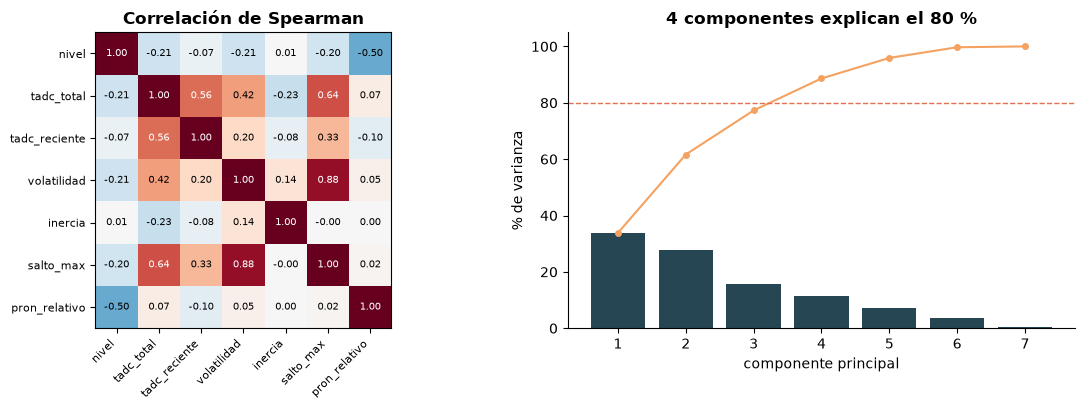

In [3]:
corr = datos[RASGOS].corr(method="spearman")
Z = StandardScaler().fit_transform(datos[RASGOS])
var = PCA().fit(Z).explained_variance_ratio_

fig, ax = plt.subplots(1, 2, figsize=(12, 4.2), gridspec_kw={"width_ratios": [1.3, 1]})
im = ax[0].imshow(corr, cmap="RdBu_r", vmin=-1, vmax=1)
ax[0].set_xticks(range(len(RASGOS)), RASGOS, rotation=45, ha="right", fontsize=8)
ax[0].set_yticks(range(len(RASGOS)), RASGOS, fontsize=8)
for i in range(len(RASGOS)):
    for j in range(len(RASGOS)):
        ax[0].text(j, i, "%.2f" % corr.iloc[i, j], ha="center", va="center", fontsize=7,
                   color="white" if abs(corr.iloc[i, j]) > .55 else "black")
ax[0].set_title("Correlación de Spearman", fontweight="bold")

ax[1].bar(range(1, len(var) + 1), 100 * var, color=AZUL)
ax[1].plot(range(1, len(var) + 1), 100 * np.cumsum(var), "o-", color=NARANJA, ms=4)
ax[1].axhline(80, color=ROJO, ls="--", lw=1)
ax[1].set_xlabel("componente principal"); ax[1].set_ylabel("% de varianza")
ax[1].set_title("%d componentes explican el 80 %%" % (np.searchsorted(np.cumsum(var), .8) + 1),
                fontweight="bold")
ax[1].spines[["top", "right"]].set_visible(False)
fig.tight_layout()

pares = corr.where(np.triu(np.ones(corr.shape), 1).astype(bool)).stack()
pares.sort_values(key=abs, ascending=False).head(4).round(2)

37 428 manzanas tienen la serie completa y pronóstico. Las siete variables siguen
sin ser independientes: volatilidad y salto máximo se repiten casi del todo
(0,88), y el nivel de precio y el pronóstico relativo van en sentido opuesto
(−0,50), que es la reversión a la media que aprendió el pronóstico.

Las colas son extremas: el salto máximo llega a 3,65 en log10, multiplicar el
valor por casi 4 500 en un año. Eso no es mercado sino una corrección
administrativa, y son las atípicas de la sección 6.2.

## 2. ¿Hay algo que agrupar?

Un algoritmo de clustering siempre devuelve grupos, incluso sobre ruido. El
estadístico de **Hopkins** compara la distancia de puntos reales a su vecino más
cercano con la de puntos sembrados al azar: 0,5 es ruido, cerca de 1 hay
estructura.

Con colas largas el número se satura, así que se compara contra los mismos datos
**barajados columna a columna**: misma distribución de cada variable, sin la
estructura conjunta. Lo que quede por encima de esa referencia es estructura de
verdad.

In [4]:
Z_barajado = np.column_stack([rng.permutation(col) for col in Z.T])
vecino = {n: NearestNeighbors(n_neighbors=2).fit(M) for n, M in [("datos", Z), ("barajados", Z_barajado)]}

hopkins = {}
for nombre, M in [("datos", Z), ("barajados", Z_barajado)]:
    valores = []
    for semilla in range(5):
        r = np.random.default_rng(semilla)
        reales = M[r.choice(len(M), 1500, replace=False)]
        artificiales = r.uniform(M.min(0), M.max(0), size=(1500, M.shape[1]))
        d_real = vecino[nombre].kneighbors(reales)[0][:, 1].sum()      # el 1o es el punto mismo
        d_art = vecino[nombre].kneighbors(artificiales, n_neighbors=1)[0][:, 0].sum()
        valores.append(d_art / (d_art + d_real))
    hopkins[nombre] = np.mean(valores)

pd.Series(hopkins, name="Hopkins").round(3)

datos        0.995
barajados    0.981
Name: Hopkins, dtype: float64

0,995 contra 0,981 de los datos barajados. Los dos están pegados al techo, y la
poca distancia entre ellos es lo informativo: buena parte de lo que parece
estructura viene de las colas de cada variable, no de cómo se combinan. Hay algo
que agrupar, pero no mucho. Los grupos van a ser más una partición útil de un
continuo que tipos separados.

## 3. Cuántos grupos

Los índices habituales miden **geometría**: qué tan compactos y separados quedan
los grupos. Ninguno dice si la partición es **reproducible**, que es lo que
decide si un k es real. La estabilidad se mide así: dos submuestras del 80 %, se
agrupa cada una por separado y se compara la etiqueta de las manzanas que están
en ambas con el índice de Rand ajustado (ARI).

| Criterio | Se busca |
|---|---|
| Inercia | el codo |
| Silueta | máximo |
| Calinski-Harabasz | máximo |
| Davies-Bouldin | mínimo |
| **Estabilidad (ARI)** | **máximo** |

,inercia,silueta,calinski_harabasz,davies_bouldin,estabilidad_ari,estabilidad_sd,grupo_mayor_pct
k,,,,,,,
2,208599.959,0.732,9580.084,0.975,0.322,0.290,97.673
3,165650.234,0.727,10883.595,0.876,0.254,0.209,96.072
4,141064.413,0.260,10694.277,1.245,0.435,0.232,64.599
5,120197.447,0.297,11037.212,1.140,0.553,0.189,58.373
6,106919.377,0.305,10855.467,1.051,0.432,0.077,59.669
7,98848.962,0.233,10293.699,1.159,0.505,0.109,45.768
8,90703.131,0.282,10095.382,1.123,0.525,0.179,45.883
9,84789.567,0.285,9775.518,1.113,0.520,0.135,44.662
10,79437.455,0.243,9554.653,1.122,0.528,0.104,31.816


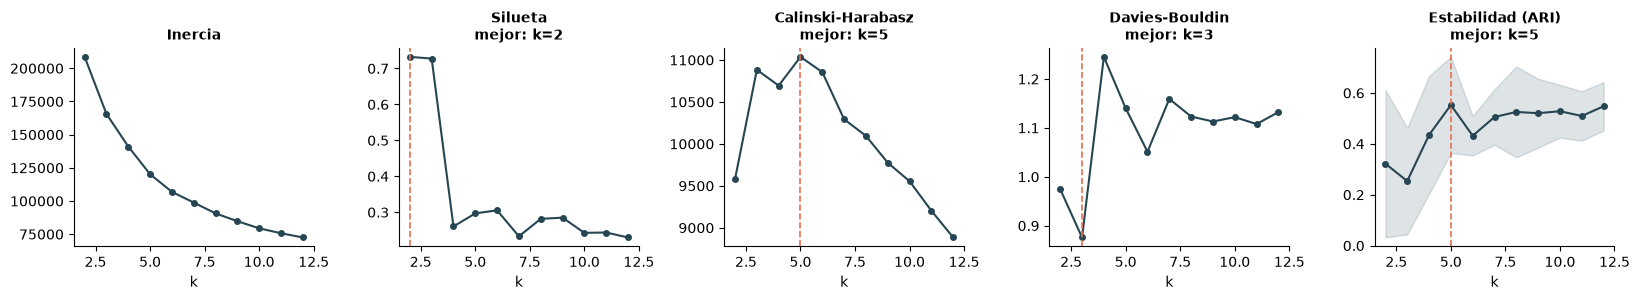

In [5]:
sub = rng.choice(len(Z), min(N_SUB, len(Z)), replace=False)
filas = []
for k in K_RANGO:
    e = KMeans(k, n_init=10, random_state=C.SEMILLA).fit(Z)
    aris = []
    for i in range(N_ESTABILIDAD):
        r = np.random.default_rng(100 * k + i)
        a = r.choice(len(Z), int(.8 * len(Z)), replace=False)
        b = r.choice(len(Z), int(.8 * len(Z)), replace=False)
        comun = np.intersect1d(a, b)
        ea = MiniBatchKMeans(k, n_init=5, batch_size=2048, random_state=C.SEMILLA).fit(Z[a])
        eb = MiniBatchKMeans(k, n_init=5, batch_size=2048, random_state=C.SEMILLA + 1).fit(Z[b])
        aris.append(adjusted_rand_score(ea.predict(Z[comun]), eb.predict(Z[comun])))
    filas.append({"k": k, "inercia": e.inertia_,
                  "silueta": silhouette_score(Z[sub], e.labels_[sub]),
                  "calinski_harabasz": calinski_harabasz_score(Z, e.labels_),
                  "davies_bouldin": davies_bouldin_score(Z, e.labels_),
                  "estabilidad_ari": np.mean(aris), "estabilidad_sd": np.std(aris),
                  "grupo_mayor_pct": 100 * np.bincount(e.labels_).max() / len(Z)})
indices = pd.DataFrame(filas).set_index("k")

fig, ax = plt.subplots(1, 5, figsize=(16.5, 3.1))
for a, (col, titulo, mejor) in zip(ax, [("inercia", "Inercia", None), ("silueta", "Silueta", "max"),
                                        ("calinski_harabasz", "Calinski-Harabasz", "max"),
                                        ("davies_bouldin", "Davies-Bouldin", "min"),
                                        ("estabilidad_ari", "Estabilidad (ARI)", "max")]):
    a.plot(indices.index, indices[col], "o-", color=AZUL, ms=4)
    if col == "estabilidad_ari":
        a.fill_between(indices.index, indices[col] - indices["estabilidad_sd"],
                       indices[col] + indices["estabilidad_sd"], color=AZUL, alpha=.15)
    if mejor:
        k_mejor = indices[col].idxmax() if mejor == "max" else indices[col].idxmin()
        a.axvline(k_mejor, color=ROJO, ls="--", lw=1.2)
        titulo += "\nmejor: k=%d" % k_mejor
    a.set_title(titulo, fontweight="bold", fontsize=10); a.set_xlabel("k")
    a.spines[["top", "right"]].set_visible(False)
fig.tight_layout()

indices.round(3)

Cuando los criterios no coinciden —casi nunca coinciden— manda la estabilidad,
con dos condiciones: que la silueta no esté entre las peores y que ningún grupo
se lleve casi todo. Una partición con un grupo del 95 % tiene silueta altísima y
no sirve para nada.

In [6]:
candidatos = indices[(indices["silueta"] >= indices["silueta"].quantile(.4))
                     & (indices["grupo_mayor_pct"] < 90)]
K = int(candidatos["estabilidad_ari"].idxmax())
print("k elegido: %d | estabilidad %.3f | silueta %.3f | grupo mayor %.1f %%"
      % (K, indices.loc[K, "estabilidad_ari"], indices.loc[K, "silueta"], indices.loc[K, "grupo_mayor_pct"]))

k elegido: 5 | estabilidad 0.553 | silueta 0.297 | grupo mayor 58.4 %


La silueta prefiere k = 2 o 3, pero con un grupo que se lleva el 96-98 % de las
manzanas: aparta un puñado de atípicas y nada más. Descartados esos, la
estabilidad elige **k = 5** (ARI 0,55).

Hay que leerla con su desviación: ±0,19 entre repeticiones, así que 5, 8, 10 o 12
son casi indistinguibles. Y ninguna partición es muy reproducible —un ARI de 0,55
es que dos muestras coinciden en algo más de la mitad de la estructura—, lo que
confirma a Hopkins: es un continuo que se corta, no grupos que se descubren.

## 4. Los algoritmos que sirvieron

En el proyecto anterior se compararon seis. Quedan los que hicieron algo útil:

| Algoritmo | Para qué se usa aquí |
|---|---|
| **K-Means** | la partición final: fue la más estable |
| **Mezcla gaussiana** | contraste, y su verosimilitud marca atípicas en la sección 6.2 |
| **DBSCAN** | su ruido es el primer detector de atípicas |

El jerárquico libre y BIRCH salen: el primero no agregaba nada distinto de K-Means
y el segundo metía el 92 % de las manzanas en un solo grupo.

La **pureza espacial** —qué fracción de los 8 vecinos geográficos de una manzana
comparte su grupo— no entró al agrupamiento, así que es un resultado. Se compara
contra lo que daría repartir las mismas etiquetas al azar, que **no es 1/k**: con
grupos desbalanceados es la suma de los cuadrados de las proporciones.

In [7]:
km = KMeans(K, n_init=10, random_state=C.SEMILLA).fit(Z)

# mezcla gaussiana: el tipo de covarianza se elige por BIC con el mismo k
bic = {cov: GaussianMixture(K, covariance_type=cov, random_state=C.SEMILLA).fit(Z).bic(Z)
       for cov in ["full", "tied", "diag", "spherical"]}
COV = min(bic, key=bic.get)
gmm = GaussianMixture(K, covariance_type=COV, n_init=3, random_state=C.SEMILLA).fit(Z)

# DBSCAN: la configuracion cuyo ruido quede mas cerca del 5 %
rejilla = []
for eps in [.5, .7, 1.0]:
    for minimo in [25, 50]:
        e = DBSCAN(eps=eps, min_samples=minimo, n_jobs=-1).fit_predict(Z)
        rejilla.append({"eps": eps, "min_samples": minimo, "ruido_pct": 100 * np.mean(e == -1),
                        "grupos": len(set(e)) - (-1 in e)})
rejilla = pd.DataFrame(rejilla)
elegida = rejilla.loc[(rejilla["ruido_pct"] - 5).abs().idxmin()]
db = DBSCAN(eps=elegida["eps"], min_samples=int(elegida["min_samples"]), n_jobs=-1).fit(Z)

print("mezcla gaussiana: covarianza '%s' por BIC" % COV)
print("DBSCAN: eps=%.1f, min_samples=%d -> %d grupos, %.1f %% de ruido"
      % (elegida["eps"], elegida["min_samples"], elegida["grupos"], elegida["ruido_pct"]))

mezcla gaussiana: covarianza 'full' por BIC
DBSCAN: eps=1.0, min_samples=25 -> 13 grupos, 5.3 % de ruido


In [8]:
xy = np.c_[datos["lon"] * np.cos(np.radians(4.65)), datos["lat"]]
vec_geo = NearestNeighbors(n_neighbors=K_VECINOS + 1).fit(xy).kneighbors(xy)[1][:, 1:]

etiquetas = {"K-Means": km.labels_, "Mezcla gaussiana": gmm.predict(Z), "DBSCAN": db.labels_}
filas = []
for nombre, e in etiquetas.items():
    ok = e != -1
    p = np.bincount(e[ok]) / ok.sum()
    filas.append({"algoritmo": nombre, "grupos": len(p), "sin_asignar_pct": 100 * (~ok).mean(),
                  "silueta": silhouette_score(Z[sub][ok[sub]], e[sub][ok[sub]]),
                  "davies_bouldin": davies_bouldin_score(Z[ok], e[ok]),
                  "grupo_mayor_pct": 100 * p.max(),
                  "pureza_espacial": np.mean(e[vec_geo] == e[:, None]),
                  "pureza_al_azar": np.sum(p ** 2),
                  "ARI_con_KMeans": adjusted_rand_score(km.labels_, e)})
pd.DataFrame(filas).set_index("algoritmo").round(3)

,grupos,sin_asignar_pct,silueta,davies_bouldin,grupo_mayor_pct,pureza_espacial,pureza_al_azar,ARI_con_KMeans
algoritmo,,,,,,,,
K-Means,5,0.000,0.297,1.140,58.373,0.864,0.435,1.000
Mezcla gaussiana,5,0.000,0.189,2.009,59.557,0.758,0.418,0.226
DBSCAN,13,5.282,0.240,0.954,65.513,0.774,0.495,0.224


K-Means es el más compacto (silueta 0,30) y el que mejor dibuja zonas: el 86 % de
los vecinos de una manzana comparte su grupo, contra 44 % si las mismas etiquetas
se repartieran al azar. El proyecto anterior comparaba contra 1/k —17 %— y la
diferencia parecía enorme; con la referencia correcta se achica, pero sigue
siendo el doble.

La mezcla gaussiana y DBSCAN coinciden poco con K-Means (ARI 0,23 y 0,22): cada
uno corta el continuo por otro lado. Por eso sirven como detectores
independientes de atípicas, no como alternativas a la partición.

## 5. Quiénes son estos grupos

Desde aquí se trabaja con K-Means. El perfil va en unidades estandarizadas: +1 es
una desviación típica por encima del promedio de la ciudad en ese rasgo. El nombre
de cada grupo lo pone una regla sobre ese perfil; es una ayuda de lectura, no una
clasificación oficial.

In [9]:
datos["cluster"] = km.labels_
perfil_z = pd.DataFrame(Z, columns=RASGOS).groupby(km.labels_).mean()

nombres = {}
for c, fila in perfil_z.iterrows():
    q = (datos["cop_m2"] < datos.loc[datos["cluster"] == c, "cop_m2"].median()).mean()
    nivel = "caro" if q > .66 else "barato" if q < .33 else "medio"
    ritmo = ("acelerando" if fila["tadc_reciente"] > .5 else
             "estancado" if fila["tadc_reciente"] < -.5 else "al ritmo de la ciudad")
    extra = " e inestable" if fila["volatilidad"] > .8 else " y quieto" if fila["inercia"] > .8 else ""
    nombres[c] = "%s, %s%s" % (nivel, ritmo, extra)

grupos = datos.groupby("cluster")
perfil = pd.DataFrame({
    "nombre": pd.Series(nombres),
    "manzanas": grupos.size(),
    "pct": (100 * grupos.size() / len(datos)).round(1),
    "precio_2026": grupos["cop_m2"].median().map(pesos),
    "tadc_total_pct": grupos["tadc_total"].median().map(pct).round(1),
    "tadc_reciente_pct": grupos["tadc_reciente"].median().map(pct).round(1),
    "volatilidad": grupos["volatilidad"].median().round(3),
    "inercia": grupos["inercia"].median().round(2)})
perfil

,nombre,manzanas,pct,precio_2026,tadc_total_pct,tadc_reciente_pct,volatilidad,inercia
0,"caro, al ritmo de la ciudad",21848,58.4,3.4 M,8.2,7.5,0.026,0.00
1,"medio, al ritmo de la ciudad y quieto",3253,8.7,2.7 M,6.2,6.6,0.035,0.25
2,"barato, estancado e inestable",608,1.6,295 k,1.0,-25.0,0.183,0.00
3,"barato, acelerando e inestable",737,2.0,1.5 M,20.7,11.5,0.318,0.00
4,"barato, al ritmo de la ciudad",10982,29.3,1.5 M,11.0,10.1,0.037,0.00


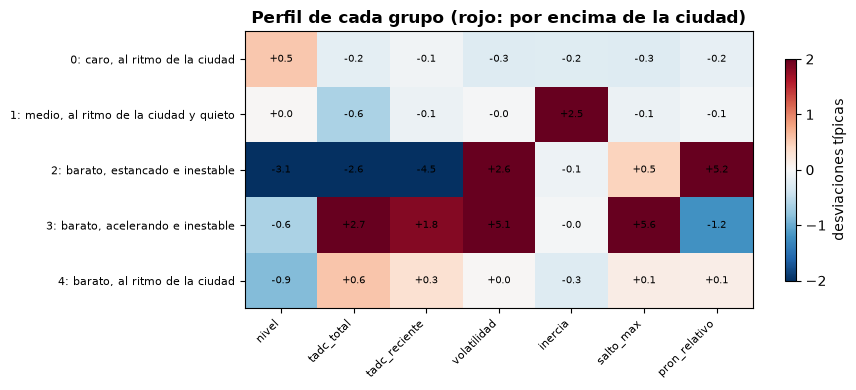

In [10]:
fig, ax = plt.subplots(figsize=(9, 0.5 * K + 1.5))
im = ax.imshow(perfil_z, cmap="RdBu_r", vmin=-2, vmax=2, aspect="auto")
ax.set_xticks(range(len(RASGOS)), RASGOS, rotation=45, ha="right", fontsize=8)
ax.set_yticks(range(K), ["%d: %s" % (c, nombres[c]) for c in perfil_z.index], fontsize=8)
for i in range(K):
    for j in range(len(RASGOS)):
        ax.text(j, i, "%+.1f" % perfil_z.iloc[i, j], ha="center", va="center", fontsize=7.5)
fig.colorbar(im, ax=ax, shrink=.8, label="desviaciones típicas")
ax.set_title("Perfil de cada grupo (rojo: por encima de la ciudad)", fontweight="bold")
fig.tight_layout();

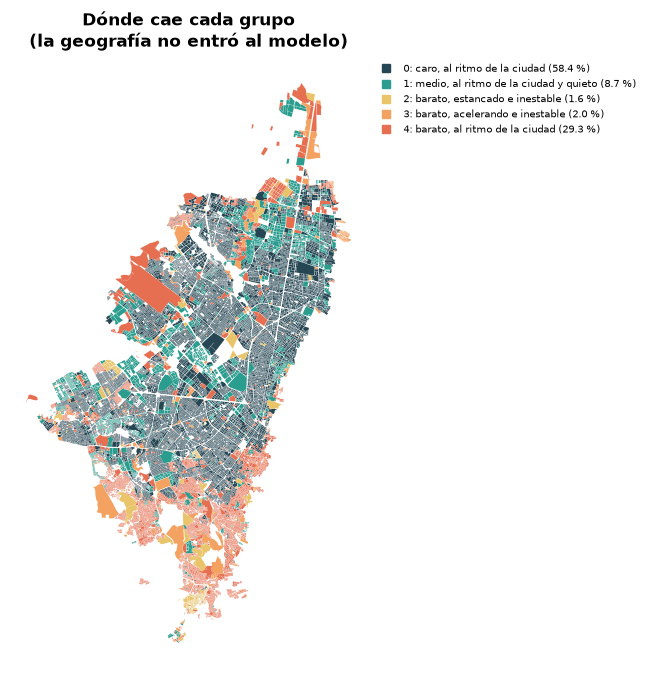

In [11]:
fig, ax = plt.subplots(figsize=TAM_MAPA)
for c in perfil.sort_values("manzanas", ascending=False).index:       # los chicos, encima
    datos[datos["cluster"] == c].plot(ax=ax, color=PALETA[c % len(PALETA)], linewidth=0)
ax.legend(handles=[plt.Line2D([], [], marker="s", ls="", color=PALETA[c % len(PALETA)],
                              label="%d: %s (%.1f %%)" % (c, nombres[c], perfil.loc[c, "pct"]))
                   for c in perfil.index],
          fontsize=7, frameon=False, loc="upper left", bbox_to_anchor=(1, 1))
ax.set_title("Dónde cae cada grupo\n(la geografía no entró al modelo)", fontweight="bold")
ax.set_axis_off();

#### Cómo leer cada grupo

El mapa de calor se lee por filas: cada celda es cuánto se aparta el grupo del
promedio de la ciudad en ese rasgo. Lo que define a un grupo son sus celdas de
color fuerte; las cercanas a 0 dicen que en eso se comporta como cualquier otra
manzana.

| Grupo | Peso | Lo que lo define | En pesos y años | Para quien compra |
|---|---|---|---|---|
| **0 · caro, al ritmo de la ciudad** | 58 % | precio +0,5 σ y todo lo demás un poco por debajo del promedio: es el grupo más **predecible** (volatilidad y saltos −0,25 σ) | mediana 3,4 M/m²; +8,2 % anual desde 2017, +7,5 % desde 2023 | el suelo consolidado: lo que se paga hoy es buena guía de lo que valdrá |
| **4 · barato, al ritmo de la ciudad** | 29 % | precio −0,9 σ con crecimiento algo mayor que el promedio (+0,6 σ en diez años) y la misma estabilidad del grupo 0 | 1,5 M/m²; +11 % anual desde 2017, +10 % desde 2023 | el barrio popular consolidado, estratos 1 y 2: más valorización porcentual sin más riesgo. Es la reversión a la media del notebook 02 |
| **1 · medio y quieto** | 9 % | **inercia +2,5 σ**: un cuarto de los años Catastro no le movió el valor; crece por debajo de la ciudad en diez años (−0,6 σ) | 2,7 M/m²; +6,2 % anual desde 2017 | un valor de referencia que se actualiza poco puede ir detrás del mercado. El precio catastral aquí informa menos que en los otros grupos |
| **3 · barato, acelerando e inestable** | 2 % | **saltos +5,6 σ y volatilidad +5,1 σ**: en la mediana, el año de mayor alza multiplicó el valor por 5,8; crece mucho en diez años (+2,7 σ) | 1,5 M/m²; +21 % anual desde 2017 | el crecimiento llega de golpe, no gradual. Concentra los sectores de la 6.1 y casi dos tercios de las atípicas de la 6.2: hay que verificar cada salto antes de proyectarlo |
| **2 · barato, estancado e inestable** | 2 % | **el más barato (−3,1 σ) y el único que cae** (−4,5 σ desde 2023), con volatilidad +2,6 σ; el pronóstico le da +5,2 σ porque espera un rebote | 295 k/m²; −25 % anual desde 2023 | periferia de estrato 1, a 11 km de la centralidad más cercana. El rebote del pronóstico es reversión a la media, no un hecho observado |

Los dos grupos grandes son el mismo comportamiento a dos niveles de precio:
juntos son el 88 % de las manzanas y se mueven con poca sorpresa. Lo interesante
está en los tres chicos, cada uno con una rareza distinta: un valor que no se
actualiza, uno que salta y uno que cae.

### Validación externa: morfología, centralidades y estrato

Ninguna de estas variables participó en el agrupamiento. Si los grupos se
diferencian también en ellas, capturaron algo del territorio y no un corte
arbitrario. La medida es el **η²**: qué fracción de la varianza de la variable
explica pertenecer a un grupo u otro. 0 es que el grupo no dice nada de esa
variable.

In [12]:
EXTERNAS = {"dist_zona_t_km": "ubicacion", "dist_calle_100_km": "ubicacion",
            "dist_centro_historico_km": "ubicacion", "dist_centro_cercano_km": "ubicacion",
            "pisos_prom_pond": "morfologia", "indice_construccion": "morfologia",
            "frac_subterraneo": "morfologia", "densidad_lotes_ha": "morfologia",
            "huella_media_m2": "morfologia", "estrato": "estrato"}

eta2 = {}
for v in EXTERNAS:
    x = datos[v]
    ok = x.notna()
    media_grupo = x[ok].groupby(datos.loc[ok, "cluster"]).transform("mean")
    eta2[v] = ((media_grupo - x[ok].mean()) ** 2).sum() / ((x[ok] - x[ok].mean()) ** 2).sum()
eta2 = pd.DataFrame({"fuente": pd.Series(EXTERNAS), "eta2": pd.Series(eta2)}).sort_values("eta2", ascending=False)

medianas = datos.groupby("cluster")[list(EXTERNAS)].median()
medianas.insert(0, "nombre", pd.Series(nombres))
print("eta2: que fraccion de la varianza de cada variable explica el grupo\n")
print(eta2.round(3).to_string())
medianas.round(2)

eta2: que fraccion de la varianza de cada variable explica el grupo

                              fuente   eta2
dist_calle_100_km          ubicacion  0.311
estrato                      estrato  0.298
dist_zona_t_km             ubicacion  0.290
dist_centro_cercano_km     ubicacion  0.220
pisos_prom_pond           morfologia  0.066
indice_construccion       morfologia  0.052
frac_subterraneo          morfologia  0.047
densidad_lotes_ha         morfologia  0.039
huella_media_m2           morfologia  0.033
dist_centro_historico_km   ubicacion  0.023


,nombre,dist_zona_t_km,dist_calle_100_km,dist_centro_historico_km,dist_centro_cercano_km,pisos_prom_pond,indice_construccion,frac_subterraneo,densidad_lotes_ha,huella_media_m2,estrato
cluster,,,,,,,,,,,
0,"caro, al ritmo de la ciudad",9.65,9.72,10.26,3.44,2.42,2.10,0.0,74.64,39.3,3.0
1,"medio, al ritmo de la ciudad y quieto",12.24,13.33,11.24,3.72,2.61,1.83,0.0,34.22,49.0,3.0
2,"barato, estancado e inestable",19.76,21.76,11.85,11.48,2.01,1.70,0.0,120.60,37.1,1.0
3,"barato, acelerando e inestable",11.73,10.77,11.28,4.90,1.94,1.00,0.0,49.14,40.5,2.0
4,"barato, al ritmo de la ciudad",15.42,17.10,9.55,5.38,2.11,1.87,0.0,112.16,35.5,2.0


**Cómo leer el η².**

$$\eta^2 = \frac{\sum_g n_g\,(\bar{x}_g - \bar{x})^2}{\sum_i (x_i - \bar{x})^2}$$

Arriba, cuánto se separan las medias de los grupos ($\bar{x}_g$, con $n_g$
manzanas cada uno) de la media de la ciudad; abajo, la varianza total. Es la
fracción de la varianza de una variable que se explica sabiendo a qué grupo
pertenece la manzana: 0 es que el grupo no dice nada, 1 es
que todas las manzanas de un grupo tienen el mismo valor. La convención habitual
toma 0,01 como efecto pequeño, 0,06 como medio y 0,14 como grande.

| Variable | η² | Lectura |
|---|---|---|
| distancia a la Calle 100 | 0,31 | **grande**. El grupo 0 está a 9,7 km en la mediana, el 4 a 17 km y el 2 a 22 km |
| estrato | 0,30 | **grande**. Mediana 3 en el grupo 0, 2 en el 4 y el 3, y 1 en el 2 (81 % de sus manzanas son estrato 1) |
| distancia a la Zona T | 0,29 | **grande**, casi igual que la Calle 100: miden lo mismo, la cercanía al norte |
| distancia a la centralidad más cercana | 0,22 | **grande**, y casi todo por el grupo 2: a 11,5 km de cualquier centro, contra 3 a 5 km del resto |
| pisos, índice de construcción, subterráneos | 0,05-0,07 | **medio** en el límite: las medianas van de 1,9 a 2,6 pisos en todos los grupos |
| densidad de lotes, tamaño de huella | 0,03-0,04 | **pequeño**. Las medianas difieren (34 contra 120 lotes por hectárea), pero dentro de cada grupo varían tanto que el grupo casi no las predice |
| distancia al centro histórico | 0,02 | **casi nulo**: todos los grupos quedan a 9,5-12 km de la Plaza de Bolívar |

Dos advertencias. El 88 % de las manzanas está en los grupos 0 y 4, así que estos
η² miden sobre todo la diferencia entre esos dos; los grupos chicos pesan poco.
Y es una asociación: que el grupo explique el 31 % de la distancia a la Calle 100
no dice que la distancia cause el comportamiento, pero sí que los grupos, hechos
sin mirar el mapa, ordenan la ciudad de norte a sur.

Cómo se mueve el precio de una manzana tiene que ver con en qué parte de la
ciudad está y con su estrato, mucho más que con lo que tiene construido. Es lo
complementario del notebook 01: la morfología ayuda a explicar el **nivel** del
precio, no su **dinámica**.

## 6. Las zonas que destacan

### 6.1 Oportunidad: crecer más de lo que el precio haría esperar

Lo barato se valoriza más rápido en porcentaje, así que "las zonas que más crecen"
es casi por definición "las más baratas". La oportunidad lo corrige:

> **oportunidad = crecimiento reciente − el crecimiento que le tocaría a una
> manzana de ese precio**

$$\text{oportunidad} = \text{tadc\_reciente} - f(\text{nivel\_inicio})$$

Lo esperado se estima con una regresión isotónica del crecimiento sobre el precio
de **2023**, el del inicio de la ventana: el de 2026 contaminaría la medida, porque
una manzana que saltó en 2024-2026 llega cara justamente por haber saltado. El
objetivo se recorta a su rango central para que media docena de revalúos del 200 %
no definan lo esperado de todo un tramo de precio.

In [13]:
# nombres para ubicar las zonas: los baja src/zonas.py. El nombre del sector
# catastral es, casi siempre, el del barrio
nombre_sector = pd.read_csv(C.SECTORES, dtype={"sector": str}).set_index("sector")["nombre_sector"]
localidades = gpd.read_file(C.LOCALIDADES)[["localidad", "geometry"]].to_crs(datos.crs)
punto = gpd.GeoDataFrame(geometry=datos.geometry.representative_point(), crs=datos.crs)
en = gpd.sjoin(punto, localidades, how="left", predicate="within")
datos["barrio"] = datos["sector"].map(nombre_sector)
datos["localidad"] = en.loc[~en.index.duplicated(), "localidad"].reindex(datos.index)
moda = lambda s: s.mode().iloc[0] if s.notna().any() else np.nan
print("manzanas sin nombre de sector: %d | sin localidad: %d"
      % (datos["barrio"].isna().sum(), datos["localidad"].isna().sum()))

manzanas sin nombre de sector: 0 | sin localidad: 0


In [14]:
recortado = datos["tadc_reciente"].clip(*np.percentile(datos["tadc_reciente"], [1, 99]))
iso = IsotonicRegression(increasing=False, out_of_bounds="clip").fit(datos["nivel_inicio"], recortado)
datos["esperado"] = iso.predict(datos["nivel_inicio"])
datos["oportunidad"] = datos["tadc_reciente"] - datos["esperado"]

print("crecimiento vs precio 2023 : %+.3f  <- la reversion a la media"
      % datos["tadc_reciente"].corr(datos["nivel_inicio"], method="spearman"))
print("oportunidad vs precio 2023 : %+.3f  <- ya descontada, debe quedar cerca de 0"
      % datos["oportunidad"].corr(datos["nivel_inicio"], method="spearman"))

por_sector = (datos.groupby("sector")
              .agg(barrio=("barrio", "first"), localidad=("localidad", moda),
                   manzanas=("MANCODIGO", "size"), precio_2026=("cop_m2", "median"),
                   crec_reciente_pct=("tadc_reciente", lambda s: pct(s.median())),
                   oportunidad_pct=("oportunidad", lambda s: pct(s.median())),
                   grupo=("cluster", lambda s: s.mode().iloc[0]))
              .query("manzanas >= 15"))
top = por_sector.nlargest(10, "oportunidad_pct").assign(
    precio_2026=lambda t: t["precio_2026"].map(pesos), grupo=lambda t: t["grupo"].map(nombres))
top.round(1)

crecimiento vs precio 2023 : -0.318  <- la reversion a la media
oportunidad vs precio 2023 : -0.042  <- ya descontada, debe quedar cerca de 0


,barrio,localidad,manzanas,precio_2026,crec_reciente_pct,oportunidad_pct,grupo
sector,,,,,,,
008543,Santa Cecilia Puente Norte,Usaquén,30,1.2 M,102.0,58.9,"barato, acelerando e inestable"
008504,La Cita,Usaquén,25,1.2 M,96.0,54.2,"barato, acelerando e inestable"
008540,La Estrellita I,Usaquén,45,1.2 M,95.5,53.8,"barato, acelerando e inestable"
002533,Sotavento,Ciudad Bolívar,34,1.7 M,33.3,23.0,"medio, al ritmo de la ciudad y quieto"
002534,Casa De Teja,Ciudad Bolívar,39,1.5 M,28.0,18.1,"barato, al ritmo de la ciudad"
008220,Siberia Central,Chapinero,45,1.9 M,27.3,17.5,"barato, al ritmo de la ciudad"
006503,Vision De Oriente,Kennedy,31,6.0 M,26.4,17.3,"caro, al ritmo de la ciudad"
004582,Renania Urapanes,Kennedy,18,4.9 M,25.1,15.5,"caro, al ritmo de la ciudad"
008101,Sagrado Corazon,Santa Fe,16,9.1 M,20.4,14.4,"caro, al ritmo de la ciudad"


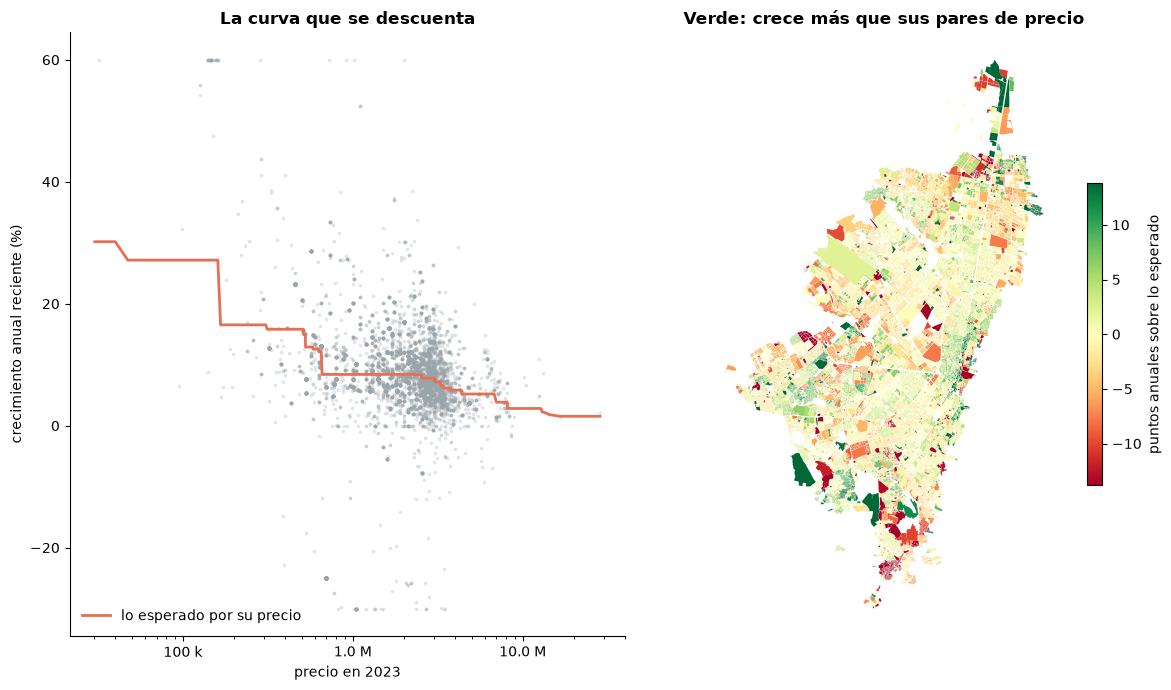

In [15]:
fig, ax = plt.subplots(1, 2, figsize=(12, 7), gridspec_kw={"width_ratios": [1, 1]})

m = datos.sample(8000, random_state=C.SEMILLA)
ax[0].scatter(10 ** m["nivel_inicio"], m["tadc_reciente"].map(pct).clip(-30, 60), s=3, alpha=.2, color=GRIS)
orden = datos.sort_values("nivel_inicio")
ax[0].plot(10 ** orden["nivel_inicio"], orden["esperado"].map(pct), color=ROJO, lw=2,
           label="lo esperado por su precio")
ax[0].set_xscale("log"); ax[0].xaxis.set_major_formatter(plt.FuncFormatter(pesos))
ax[0].set_xlabel("precio en %d" % ANIO_RECIENTE); ax[0].set_ylabel("crecimiento anual reciente (%)")
ax[0].set_title("La curva que se descuenta", fontweight="bold"); ax[0].legend(frameon=False)
ax[0].spines[["top", "right"]].set_visible(False)

lim = np.nanpercentile(np.abs(datos["oportunidad"].map(pct)), 96)
datos.assign(o=datos["oportunidad"].map(pct)).plot(
    column="o", cmap="RdYlGn", vmin=-lim, vmax=lim, linewidth=0, ax=ax[1], legend=True,
    legend_kwds={"shrink": .5, "label": "puntos anuales sobre lo esperado"})
ax[1].set_title("Verde: crece más que sus pares de precio", fontweight="bold")
ax[1].set_axis_off()
fig.tight_layout();

Descontada la reversión a la media, la correlación de la oportunidad con el
precio baja de −0,32 a −0,04: la medida ya no es un ranking de zonas baratas.
Entre los diez sectores con más oportunidad hay tres caros —6,0 M, 4,9 M y 9,1 M—
que crecen entre 14 y 17 puntos por encima de sus pares de precio.

Los tres primeros, que casi duplicaron su valor cada año del último trienio, no
son lo que parecen. Son tres de las zonas atípicas de la sección 6.2 (Santa
Cecilia Puente Norte, La Cita y La Estrellita I, en el borde norte de Usaquén) y
comparten un **2023 hundido**: ese año el valor cayó a entre la cuarta y la
séptima parte, y en 2024 volvió. Como la oportunidad se mide desde 2023, el
crecimiento sale enorme. Hay que verificarlo antes de creerlo.

### 6.2 Atípicas: las que no se parecen a nada

Tres detectores independientes, porque cada uno ve una rareza distinta:

- **ruido de DBSCAN**: la manzana está en una región de baja densidad;
- **verosimilitud baja en la mezcla gaussiana** (1 % inferior): ninguna componente
  la explica;
- **lejos de su centroide** (1 % superior): pertenece a un grupo, pero mal.

Lo que interesa es la coincidencia: una manzana marcada por dos o tres no es un
capricho del método.

In [16]:
datos["at_ruido"] = db.labels_ == -1
datos["at_verosimilitud"] = gmm.score_samples(Z) < np.percentile(gmm.score_samples(Z), 1)
lejania = np.linalg.norm(Z - km.cluster_centers_[km.labels_], axis=1)
datos["at_lejania"] = lejania > np.percentile(lejania, 99)
datos["n_detectores"] = datos[["at_ruido", "at_verosimilitud", "at_lejania"]].sum(axis=1)
atipicas = datos[datos["n_detectores"] >= 2]

desv = datos[RASGOS].std()
comparacion = pd.DataFrame({"atipicas": atipicas[RASGOS].median(),
                            "resto": datos.loc[datos["n_detectores"] < 2, RASGOS].median()})
comparacion["distancia_en_sigmas"] = (comparacion["atipicas"] - comparacion["resto"]) / desv

print("ruido DBSCAN %d | verosimilitud baja %d | lejos del centroide %d"
      % (datos["at_ruido"].sum(), datos["at_verosimilitud"].sum(), datos["at_lejania"].sum()))
print("marcadas por dos o mas: %d (%.1f %%) | por los tres: %d"
      % (len(atipicas), 100 * len(atipicas) / len(datos), (datos["n_detectores"] == 3).sum()))
comparacion.round(3)

ruido DBSCAN 1977 | verosimilitud baja 375 | lejos del centroide 375
marcadas por dos o mas: 494 (1.3 %) | por los tres: 212


,atipicas,resto,distancia_en_sigmas
nivel,6.079,6.450,-1.383
tadc_total,0.038,0.037,0.063
tadc_reciente,0.049,0.034,0.427
volatilidad,0.377,0.030,5.782
inercia,0.125,0.000,1.198
salto_max,0.757,0.093,5.359
pron_relativo,-0.085,0.000,-0.116


494 manzanas (1,3 %) marcadas por al menos dos detectores, 212 por los tres. Lo
que las distingue es la volatilidad (5,8 desviaciones por encima del resto) y el
salto máximo (5,4): no crecen distinto en promedio, se mueven a sacudidas. Son
más baratas (−1,4 σ) y tienen más años sin cambio.

#### Las zonas

Una manzana atípica sola puede ser un error de digitación; varias juntas que
saltan el mismo año son algo que pasó en la zona. Por eso se agrupan por **sector
catastral** y se llama **zona** a todo sector con 3 o más atípicas. A cada
manzana se le asigna un **patrón**, según cuál de sus rasgos de historia se aparta
más de la ciudad: un **bache** (un año hundido entre dos normales: el
valor cae y al año siguiente rebota), un **salto** de un año, una **caída**, un
**alza** sostenida o un valor **quieto**. Si ningún rasgo de la historia pasa
de 2 desviaciones, la manzana es atípica por su **precio** o su **pronóstico**. El bache va primero porque es lo que
más distorsiona: la tasa reciente medida desde el año hundido sale enorme. La zona toma el patrón más frecuente entre sus atípicas.

La tabla muestra las más relevantes, ordenadas por número de atípicas. Columnas:

- **atípicas / manzanas**: cuántas de las manzanas del sector son atípicas.
- **qué pasó**: el patrón contado en la serie. "×6,7 en 2024 (30/30)" quiere decir
  que el valor se multiplicó por 6,7 ese año (la mediana de la zona) y que 30 de
  sus 30 atípicas saltaron ese mismo año.
- **fuerza**: la mayor de la zona, en desviaciones típicas. 3 ya es raro.
- **mapa**: abre el centro de la zona en Google Maps.

In [17]:
NOMBRE_DET = {"at_ruido": "DBSCAN", "at_verosimilitud": "mezcla", "at_lejania": "centroide"}
HISTORIA = ["tadc_total", "tadc_reciente", "volatilidad", "inercia", "salto_max"]
z_at = pd.DataFrame(Z, columns=RASGOS, index=datos.index).loc[atipicas.index]
g_at = G.loc[atipicas["MANCODIGO"]].set_axis(atipicas.index)
anios = g_at.shape[1]
veces = lambda x: "{:,.0f}".format(x).replace(",", " ") if x >= 10 else ("%.1f" % x).replace(".", ",")
google = lambda la, lo: "https://www.google.com/maps?q=%.6f,%.6f" % (la, lo)

ficha = datos.loc[atipicas.index, ["MANCODIGO", "sector", "barrio", "localidad", "cop_m2", "estrato", "uso",
                                   "cluster", "lat", "lon", "n_detectores"] + HISTORIA].copy()
ficha["detectores"] = atipicas[list(NOMBRE_DET)].apply(
    lambda f: ", ".join(NOMBRE_DET[d] for d in NOMBRE_DET if f[d]), axis=1)
ficha["fuerza_sigmas"] = z_at.abs().max(axis=1)
ficha["anio_salto"], ficha["x_salto"] = g_at.idxmax(axis=1), 10 ** g_at.max(axis=1)
ficha["anio_caida"], ficha["x_caida"] = g_at.idxmin(axis=1), 10 ** g_at.min(axis=1)

# patron: el rasgo de historia que mas se aparta de la ciudad; si ninguno pasa de 2 sigmas,
# la manzana es atipica por su precio o su pronostico, no por su historia
dominante = z_at[HISTORIA].abs().idxmax(axis=1)
sin_historia = z_at[HISTORIA].abs().max(axis=1) < 2
dominante[sin_historia] = z_at.loc[sin_historia, ["nivel", "pron_relativo"]].abs().idxmax(axis=1)
# el signo del valor real (una tasa positiva pero bajo el promedio no es una caida)
signo = pd.Series([ficha.at[i, r] if r in HISTORIA else z_at.at[i, r] for i, r in dominante.items()],
                  index=dominante.index)
# un año hundido entre dos normales (cae y al siguiente rebota) manda sobre lo demas: es lo que
# infla la tasa reciente y la volatilidad
bache = ((ficha["anio_salto"] == ficha["anio_caida"] + 1) & (ficha["x_caida"] < .5) & (ficha["x_salto"] > 2))
ficha["patron"] = np.select([bache, dominante.isin(["salto_max", "volatilidad"]), dominante == "inercia",
                             dominante == "pron_relativo", dominante == "nivel", signo < 0],
                            ["bache", "salto", "quieta", "pronóstico", "precio", "caída"], "alza")
ficha["rasgo_patron"] = dominante


def frase(f, rasgo):
    """El rasgo extremo, dicho como lo que le paso a la serie."""
    if rasgo in ("salto_max", "volatilidad"):
        sube, baja = "×" + veces(f["x_salto"]), "÷" + veces(1 / f["x_caida"])
        if f["x_caida"] >= .67:
            return "salto %s en %d" % (sube, f["anio_salto"])
        if f["anio_caida"] == f["anio_salto"] - 1:
            return "%d cae %s y %d rebota %s" % (f["anio_caida"], baja, f["anio_salto"], sube)
        if f["anio_salto"] == f["anio_caida"] - 1:
            return "%d sube %s y %d se devuelve %s" % (f["anio_salto"], sube, f["anio_caida"], baja)
        return ", ".join("%d %s %s" % t for t in sorted([(f["anio_salto"], "sube", sube),
                                                         (f["anio_caida"], "cae", baja)]))
    if rasgo == "nivel":
        return "precio de %s, %s que la ciudad" % (pesos(f["cop_m2"]),
                                                  "muy por debajo" if z_at.loc[f.name, rasgo] < 0 else "muy por encima")
    if rasgo == "inercia":
        return "%d de %d años sin cambio de valor" % (round(f["inercia"] * anios), anios)
    if rasgo in ("tadc_reciente", "tadc_total"):
        return "%s %.0f %% anual desde %d" % ("crece" if f[rasgo] > 0 else "cae", abs(pct(f[rasgo])),
                                              ANIO_RECIENTE if rasgo == "tadc_reciente" else C.ANIO_INI)
    return "pronóstico %+.1f puntos anuales frente a la ciudad" % atipicas.at[f.name, "pron_relativo"]


def por_que(f):
    frases = []
    for rasgo in z_at.loc[f.name].abs().sort_values(ascending=False).index[:2]:
        if abs(z_at.loc[f.name, rasgo]) < 2 and frases:     # el segundo solo si pasa de 2 sigmas
            break
        t = frase(f, rasgo)
        if t not in frases:
            frases.append(t)
    return "; ".join(frases)


ficha["por_que"] = ficha.apply(por_que, axis=1)
ficha["grupo"] = ficha["cluster"].map(nombres)
ficha["mapa"] = [google(la, lo) for la, lo in zip(ficha["lat"], ficha["lon"])]
ficha = ficha.sort_values(["n_detectores", "fuerza_sigmas"], ascending=False)


def que_paso(z):
    """El patron mas comun de la zona, contado en la serie."""
    p = z["patron"].mode().iloc[0]
    s = z[z["patron"] == p]
    if p == "salto":
        anio = s["anio_salto"].mode().iloc[0]
        return "salto ×%s en %d (%d/%d)" % (veces(s["x_salto"].median()), anio,
                                            (z["anio_salto"] == anio).sum(), len(z))
    if p == "bache":
        anio = s["anio_caida"].mode().iloc[0]
        return "%d cae ÷%s y %d rebota ×%s (%d/%d)" % (anio, veces(1 / s["x_caida"].median()), anio + 1,
                                                      veces(s["x_salto"].median()),
                                                      (z["anio_caida"] == anio).sum(), len(z))
    if p == "pronóstico":
        return "pronóstico %+.0f puntos anuales frente a la ciudad" % atipicas.loc[s.index, "pron_relativo"].median()
    if p == "precio":
        return "precio de %s, extremo para la ciudad" % pesos(s["cop_m2"].median())
    if p == "quieta":
        return "%d de %d años sin cambio" % (round(s["inercia"].median() * anios), anios)
    rasgo = s["rasgo_patron"].mode().iloc[0]
    return "%s %.0f %% anual desde %d" % ("caen" if p == "caída" else "suben", abs(pct(s[rasgo].median())),
                                          ANIO_RECIENTE if rasgo == "tadc_reciente" else C.ANIO_INI)


zonas = (ficha.groupby("sector")
         .apply(lambda z: pd.Series({
             "barrio": z["barrio"].iloc[0], "localidad": moda(z["localidad"]),
             "atipicas": len(z), "patron": z["patron"].mode().iloc[0], "que_paso": que_paso(z),
             "precio_2026": z["cop_m2"].median(), "estrato": z["estrato"].median(),
             "grupo": z["grupo"].mode().iloc[0], "fuerza_max": z["fuerza_sigmas"].max(),
             "lat": z["lat"].mean(), "lon": z["lon"].mean()}))
         .assign(manzanas_sector=lambda t: datos.groupby("sector").size().reindex(t.index))
         .sort_values(["atipicas", "fuerza_max"], ascending=False))
zonas["mapa"] = [google(la, lo) for la, lo in zip(zonas["lat"], zonas["lon"])]
relevantes = zonas[zonas["atipicas"] >= 3].copy()
relevantes.insert(0, "n", range(1, len(relevantes) + 1))

print("%d zonas (sectores con 3 o más atípicas) reúnen %d de las %d atípicas (%.0f %%); "
      "las otras %d están sueltas en %d sectores"
      % (len(relevantes), relevantes["atipicas"].sum(), len(ficha), 100 * relevantes["atipicas"].sum() / len(ficha),
         len(ficha) - relevantes["atipicas"].sum(), len(zonas) - len(relevantes)))
print("patrón de las zonas:", relevantes["patron"].value_counts().to_dict())

N_TABLA = 12
(relevantes.head(N_TABLA)
 .assign(atipicas=lambda t: t["atipicas"].astype(int).astype(str) + " / " + t["manzanas_sector"].astype(str))
 [["n", "barrio", "localidad", "atipicas", "que_paso", "precio_2026", "estrato", "grupo", "fuerza_max", "mapa"]]
 .rename(columns={"atipicas": "atípicas / manzanas", "que_paso": "qué pasó", "precio_2026": "precio 2026",
                  "fuerza_max": "fuerza"})
 .style.format({"precio 2026": pesos, "estrato": "{:.0f}", "fuerza": "{:.1f}",
                "mapa": lambda u: '<a href="%s" target="_blank">abrir</a>' % u}, na_rep="—"))

34 zonas (sectores con 3 o más atípicas) reúnen 272 de las 494 atípicas (55 %); las otras 222 están sueltas en 190 sectores
patrón de las zonas: {'bache': 17, 'alza': 8, 'salto': 4, 'caída': 3, 'pronóstico': 1, 'quieta': 1}


,n,barrio,localidad,atípicas / manzanas,qué pasó,precio 2026,estrato,grupo,fuerza,mapa
sector,,,,,,,,,,
008540,1,La Estrellita I,Usaquén,38 / 45,"2023 cae ÷4,4 y 2024 rebota ×6,0 (38/38)",1.2 M,2,"barato, acelerando e inestable",9.7,abrir
008520,2,Bosque De Pinos,Usaquén,31 / 56,"2023 cae ÷7,0 y 2024 rebota ×6,9 (25/31)",1.2 M,1,"barato, acelerando e inestable",11.2,abrir
008543,3,Santa Cecilia Puente Norte,Usaquén,30 / 30,"2023 cae ÷6,0 y 2024 rebota ×6,7 (30/30)",1.2 M,1,"barato, acelerando e inestable",11.1,abrir
008504,4,La Cita,Usaquén,16 / 25,"2023 cae ÷4,5 y 2024 rebota ×6,2 (16/16)",1.2 M,1,"barato, acelerando e inestable",10.0,abrir
009250,5,Tibabuyes Occidental,Suba,15 / 76,salto ×16 en 2020 (13/15),2.0 M,2,"barato, acelerando e inestable",8.9,abrir
008220,6,Siberia Central,Chapinero,15 / 45,suben 31 % anual desde 2017,3.9 M,1,"barato, acelerando e inestable",6.5,abrir
008542,7,Tibabita I,Usaquén,10 / 10,"2023 cae ÷5,0 y 2024 rebota ×6,9 (10/10)",1.2 M,1,"barato, acelerando e inestable",9.8,abrir
005670,8,La Riviera,Engativá,7 / 42,2019 cae ÷12 y 2020 rebota ×15 (7/7),3.0 M,2,"barato, acelerando e inestable",9.6,abrir
005675,9,Bolivia,Engativá,7 / 77,2019 cae ÷12 y 2020 rebota ×13 (7/7),3.2 M,2,"barato, acelerando e inestable",9.0,abrir


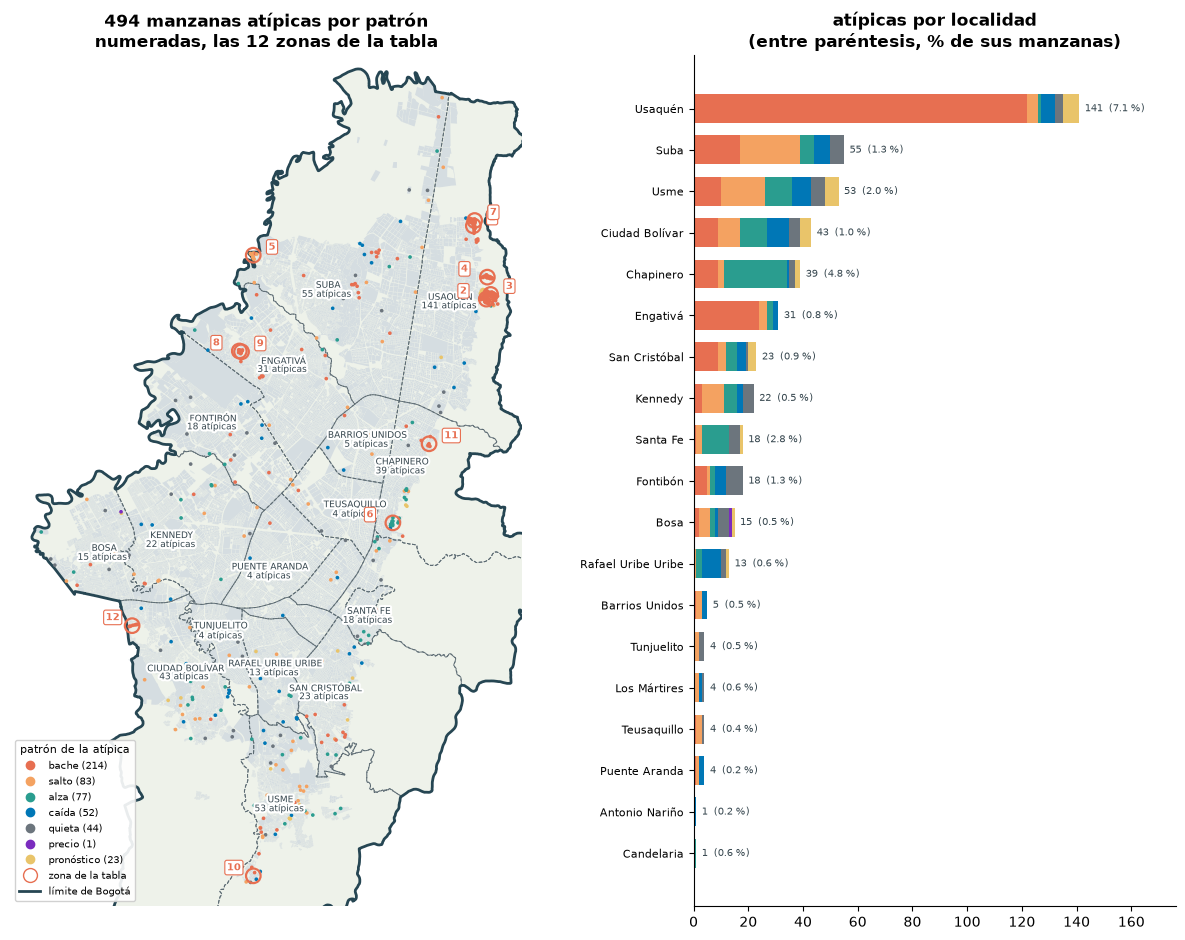

In [18]:
# el mapa con su contexto: borde de Bogota, localidades y el patron de cada atipica
import matplotlib.patheffects as pe
from matplotlib.lines import Line2D

PATRONES = {"bache": ROJO, "salto": NARANJA, "alza": VERDE, "caída": "#0077b6",
            "quieta": "#6c757d", "precio": "#7b2cbf", "pronóstico": "#e9c46a"}
bogota = localidades.dissolve()
por_localidad = (datos.groupby("localidad")
                 .agg(manzanas=("MANCODIGO", "size"), precio_2026=("cop_m2", "median"),
                      lon=("lon", "median"), lat=("lat", "median"))
                 .join(ficha.groupby("localidad").agg(atipicas=("MANCODIGO", "size"),
                                                      patron=("patron", lambda s: s.mode().iloc[0])))
                 .join(relevantes.groupby("localidad").size().rename("zonas"))
                 .fillna({"atipicas": 0, "zonas": 0})
                 .astype({"atipicas": int, "zonas": int}))
por_localidad["pct_atipicas"] = 100 * por_localidad["atipicas"] / por_localidad["manzanas"]
por_localidad = por_localidad.sort_values("atipicas", ascending=False)

fig, (ax, bx) = plt.subplots(1, 2, figsize=(13, 9.5), gridspec_kw={"width_ratios": [1.45, 1]})
localidades.plot(ax=ax, color="#eef2ea", edgecolor="none")              # cerros y suelo rural
datos.plot(ax=ax, color="#d5dde1", linewidth=0)                         # la ciudad construida
localidades.boundary.plot(ax=ax, color="#5c6b73", linewidth=.7, linestyle="--")
bogota.boundary.plot(ax=ax, color=AZUL, linewidth=2)
punto_at = ficha.assign(color=ficha["patron"].map(PATRONES))
ax.scatter(punto_at["lon"], punto_at["lat"], s=7, c=punto_at["color"], linewidth=0, zorder=3)
halo = [pe.withStroke(linewidth=3, foreground="white")]
# las localidades de menos de 8 km2 no caben con nombre; quedan en las barras
chicas = set(localidades.loc[localidades.to_crs(9377).area < 8e6, "localidad"])
for nombre, l in por_localidad.drop(index=list(chicas), errors="ignore").iterrows():
    texto = nombre.upper() + ("\n%d atípicas" % l["atipicas"] if l["atipicas"] else "")
    ax.text(l["lon"], l["lat"], texto, fontsize=6.5, color="#37474f", ha="center", va="center",
            path_effects=halo, zorder=4, linespacing=1.1)
for _, z in relevantes.head(N_TABLA).iterrows():
    ax.scatter(z["lon"], z["lat"], s=110, facecolor="none", edgecolor=ROJO, lw=1.6, zorder=5)
    ax.annotate(str(z["n"]), (z["lon"], z["lat"]), xytext=(11, 4) if z["n"] % 2 else (-19, 4),  # pares a la izquierda
                textcoords="offset points", fontsize=7.5, color=ROJO, fontweight="bold", zorder=6,
                bbox=dict(boxstyle="round,pad=.2", fc="white", ec=ROJO, lw=.8))
x0, y0, x1, y1 = datos.total_bounds
ax.set_xlim(x0 - .01, x1 + .01); ax.set_ylim(y0 - .01, y1 + .01)
ax.legend([Line2D([], [], marker="o", ls="", color=col, markersize=6) for col in PATRONES.values()] +
          [Line2D([], [], marker="o", ls="", mfc="none", mec=ROJO, markersize=10),
           Line2D([], [], color=AZUL, lw=2)],
          ["%s (%d)" % (k, (ficha["patron"] == k).sum()) for k in PATRONES] +
          ["zona de la tabla", "límite de Bogotá"],
          loc="lower left", fontsize=7.5, title="patrón de la atípica", title_fontsize=8, framealpha=.9)
ax.set_title("%d manzanas atípicas por patrón\nnumeradas, las %d zonas de la tabla" % (len(ficha), N_TABLA),
             fontweight="bold")
ax.set_axis_off()

# a la derecha, cuantas atipicas tiene cada localidad y de que tipo
con = por_localidad[por_localidad["atipicas"] > 0].iloc[::-1]
mezcla = pd.crosstab(ficha["localidad"], ficha["patron"]).reindex(index=con.index, columns=list(PATRONES), fill_value=0)
izq = np.zeros(len(mezcla))
for patron, col in PATRONES.items():
    bx.barh(mezcla.index, mezcla[patron], left=izq, color=col, height=.7)
    izq += mezcla[patron].values
for y, (n, p) in enumerate(zip(con["atipicas"], con["pct_atipicas"])):
    bx.text(n + 2, y, "%d  (%.1f %%)" % (n, p), va="center", fontsize=7.5, color="#37474f")
bx.set_xlim(0, con["atipicas"].max() * 1.25)
bx.set_title("atípicas por localidad\n(entre paréntesis, % de sus manzanas)", fontweight="bold")
bx.tick_params(axis="y", labelsize=8)
bx.spines[["top", "right"]].set_visible(False)
fig.tight_layout();

#### Lo que muestran las zonas

En 10 de las 12 zonas de la tabla todas las atípicas, o casi todas, cambiaron
**el mismo año**. No son manzanas sueltas con un dato raro: algo cambió en la zona
entera, o en cómo Catastro la valoró ese año.

- **El borde norte de Usaquén** (zonas 1, 2, 3, 4 y 7: La Estrellita I, Bosque de
  Pinos, Santa Cecilia Puente Norte, La Cita y Tibabita I). Es el foco más grande:
  125 atípicas, una de cada cuatro. Todas tienen el mismo **2023 hundido**: el
  valor cayó a entre la cuarta y la séptima parte y en 2024 volvió multiplicado
  por 6 o 7. En Santa Cecilia y Tibabita son el 100 % de las manzanas del
  sector. Hoy valen 1,2 M/m², son de estrato 1 y 2, y son las tres primeras
  "oportunidades" de la 6.1. Ese crecimiento sale del año hundido.
- **El mismo bache en 2019-2020**, en Engativá (zonas 8 y 9: La Riviera y Bolivia)
  y en El Refugio, Chapinero (zona 11). En El Refugio el valor cayó a 1/75 en 2019
  y se multiplicó por 83 en 2020; es estrato 6 y hoy vale 8,4 M/m². La manzana más
  atípica de toda la ciudad también está en Bolivia, aunque suelta: su valor de
  2019 es 4 000 veces menor que el de los años vecinos.
- **El bache en 2020-2021** en el sur: Centro Usme Urbano (zona 10) y El Mirador
  de La Estancia, Ciudad Bolívar (zona 12), con rebotes de ×48 y ×57.
- **Saltos sin caída previa**: Tibabuyes Occidental, en Suba (zona 5). El valor
  se multiplicó por 16 en 2020 en 13 de sus 15 atípicas (de 96 k a 1,55 M/m² en la
  mediana) y desde entonces crece al ritmo normal.
- **Alza fuerte con salto final**: Siberia Central, en Chapinero (zona 6), sube
  31 % anual desde 2017, contra 9 % de la ciudad. Pasó de 340 k a 1 M/m² entre 2017
  y 2021, y en 2026 saltó ×3,4, de 1,15 M a 3,9 M/m².

En el CSV, fuera de la tabla, hay **zonas que caen**: Diana Turbay Arrayanes
(Rafael Uribe Uribe), México (Ciudad Bolívar) y Charala (Usme) pierden entre 39 %
y 68 % anual desde 2023 y valen entre 50 k y 290 k/m². El pronóstico les da un
rebote fuerte, pero es reversión a la media, no algo observado.

#### Para seguir investigando

La tabla se queda en las zonas más relevantes; el resto está en tres archivos de
`data/processed/`:

| Archivo | Qué trae |
|---|---|
| `atipicas_zonas.csv` | todos los sectores con alguna atípica, con las mismas columnas de la tabla |
| `atipicas_manzanas.csv` | las 494 manzanas, una por fila: barrio, localidad, detectores, fuerza, el porqué en palabras (por ejemplo "2019 cae ÷4 132 y 2020 rebota ×4 491"), años y tamaño del salto y de la caída, y enlace a Google Maps. Están ordenadas de la más fuerte a la más débil, así que las manzanas sueltas más raras aparecen arriba |
| `atipicas_mapa.html` | mapa interactivo para acercarse hasta la cuadra. Trae fondo claro, oscuro, satélite o de calles, el límite de Bogotá, las localidades coloreadas por su porcentaje de atípicas (con su resumen al pasar el cursor), las atípicas por patrón y las zonas numeradas. Al pasar el cursor sale la ficha de cada manzana; al hacer clic, el enlace a Google Maps. Tiene buscador de barrio y pantalla completa. Abre en cualquier navegador |

Para buscar una manzana en el visor de Catastro se usa su código (`MANCODIGO`).

El cuaderno no atribuye causas. Un cambio así puede venir de un cambio de norma,
un englobe, una obra, un error de digitación o un revalúo de Catastro, y
distinguirlos exige ir al sitio, al certificado catastral o a la curaduría. Esa
verificación queda en manos de quien vaya a comprar.

In [19]:
COLUMNAS_FICHA = ["MANCODIGO", "sector", "barrio", "localidad", "detectores", "n_detectores", "fuerza_sigmas",
                  "patron", "por_que", "cop_m2", "estrato", "uso", "grupo", "anio_salto", "x_salto",
                  "anio_caida", "x_caida", "lat", "lon", "mapa"]
ficha[COLUMNAS_FICHA].to_csv(C.PROC / "atipicas_manzanas.csv", index=False, encoding="utf-8-sig")
zonas.drop(columns="patron").to_csv(C.PROC / "atipicas_zonas.csv", encoding="utf-8-sig")

# el mapa interactivo: fondos, localidades con su resumen, borde de Bogota, atipicas por patron y zonas
from branca.colormap import LinearColormap
from folium import plugins

CAMPOS = ["MANCODIGO", "barrio", "localidad", "patron", "por_que", "detectores", "fuerza", "precio", "grupo"]
ALIAS = ["manzana", "barrio", "localidad", "patrón", "qué pasó", "detectores", "fuerza (σ)", "precio 2026", "grupo"]
capa = (atipicas[["geometry"]].join(ficha)
        .assign(precio=lambda t: t["cop_m2"].map(pesos), fuerza=lambda t: t["fuerza_sigmas"].round(1),
                google=lambda t: '<a href="' + t["mapa"] + '" target="_blank">abrir en Google Maps</a>',
                geometry=lambda t: t.geometry.simplify(1e-5))
        [CAMPOS + ["google", "geometry"]])

capa_loc = (localidades.merge(por_localidad.drop(columns=["lon", "lat"]), left_on="localidad", right_index=True,
                              how="left")
            .fillna({"manzanas": 0, "atipicas": 0, "zonas": 0, "pct_atipicas": 0, "patron": "—"})
            .assign(precio=lambda t: t["precio_2026"].map(lambda v: pesos(v) if v == v else "—"),
                    pct=lambda t: t["pct_atipicas"].round(1),
                    geometry=lambda t: t.geometry.simplify(2e-4))
            [["localidad", "manzanas", "atipicas", "pct", "zonas", "patron", "precio", "geometry"]])
escala = LinearColormap(["#fff5eb", "#fdbe85", "#e6550d"], vmin=0, vmax=float(capa_loc["pct"].max()),
                        caption="% de manzanas atípicas en la localidad")

x0, y0, x1, y1 = datos.total_bounds
mapa = folium.Map(location=[(y0 + y1) / 2, (x0 + x1) / 2], zoom_start=11, tiles=None, control_scale=True)
# fondos que cargan sin clave tambien al abrir el HTML como archivo local (CARTO la exige)
ESRI = "https://server.arcgisonline.com/ArcGIS/rest/services/%s/MapServer/tile/{z}/{y}/{x}"
for nombre, servicio, attr in [("fondo claro", "Canvas/World_Light_Gray_Base", "Esri, HERE, Garmin"),
                               ("fondo oscuro", "Canvas/World_Dark_Gray_Base", "Esri, HERE, Garmin"),
                               ("satélite", "World_Imagery", "Esri, Maxar, Earthstar Geographics")]:
    folium.TileLayer(ESRI % servicio, attr=attr, name=nombre, max_native_zoom=16 if "Canvas" in servicio else 19,
                     max_zoom=19, show=nombre == "fondo claro").add_to(mapa)
folium.TileLayer("OpenStreetMap", name="calles", show=False).add_to(mapa)

folium.GeoJson(capa_loc, name="localidades",
               style_function=lambda f: {"fillColor": escala(f["properties"]["pct"]), "fillOpacity": .45,
                                         "color": "#455a64", "weight": 1.5, "dashArray": "5 4"},
               highlight_function=lambda f: {"weight": 3, "fillOpacity": .65},
               tooltip=folium.GeoJsonTooltip(
                   ["localidad", "manzanas", "atipicas", "pct", "zonas", "patron", "precio"],
                   aliases=["localidad", "manzanas urbanas", "atípicas", "% atípicas", "zonas (3+ atípicas)",
                            "patrón más común", "precio mediano 2026"], sticky=True)).add_to(mapa)
escala.add_to(mapa)
folium.GeoJson(bogota.boundary, name="límite de Bogotá", interactive=False,
               style_function=lambda f: {"color": AZUL, "weight": 4, "opacity": .9}).add_to(mapa)

nombres_loc = folium.FeatureGroup(name="nombres de localidad")
for nombre, l in por_localidad.drop(index=list(chicas), errors="ignore").iterrows():
    folium.Marker([l["lat"], l["lon"]], icon=folium.DivIcon(
        icon_size=(150, 30), icon_anchor=(75, 15),
        html='<div style="text-align:center;font:600 11px sans-serif;color:#263238;letter-spacing:.5px;'
             'text-shadow:0 0 3px #fff,0 0 3px #fff,0 0 3px #fff">%s<br><span style="font-weight:400">'
             '%d atípicas</span></div>' % (nombre.upper(), l["atipicas"]))).add_to(nombres_loc)
nombres_loc.add_to(mapa)

capa_at = folium.GeoJson(capa, name="manzanas atípicas",
                         style_function=lambda f: {"fillColor": PATRONES[f["properties"]["patron"]],
                                                   "color": PATRONES[f["properties"]["patron"]],
                                                   "weight": 1.5, "fillOpacity": .8},
                         highlight_function=lambda f: {"weight": 4, "color": "#000"},
                         tooltip=folium.GeoJsonTooltip(CAMPOS, aliases=ALIAS, sticky=True),
                         popup=folium.GeoJsonPopup(["MANCODIGO", "barrio", "por_que", "google"],
                                                   aliases=["manzana", "barrio", "qué pasó", ""]))
capa_at.add_to(mapa)

capa_zonas = folium.FeatureGroup(name="zonas (sectores con 3+ atípicas)")
for _, z in relevantes.iterrows():
    lado = int(18 + 2.2 * np.sqrt(z["atipicas"]))
    ficha_zona = ("<b>zona %d · %s</b><br>%s<br>%d de %d manzanas atípicas<br>qué pasó: %s<br>"
                  "precio 2026: %s · estrato %s<br>grupo: %s<br><a href='%s' target='_blank'>abrir en Google Maps</a>"
                  % (z["n"], z["barrio"], z["localidad"], z["atipicas"], z["manzanas_sector"], z["que_paso"],
                     pesos(z["precio_2026"]), "%.0f" % z["estrato"] if z["estrato"] == z["estrato"] else "—",
                     z["grupo"], z["mapa"]))
    folium.Marker([z["lat"], z["lon"]], tooltip="zona %d · %s (%s)" % (z["n"], z["barrio"], z["localidad"]),
                  popup=folium.Popup(ficha_zona, max_width=320),
                  icon=folium.DivIcon(icon_size=(lado, lado), icon_anchor=(lado // 2, lado // 2),
                                      html='<div style="width:%dpx;height:%dpx;border-radius:50%%;background:#fff;'
                                           'border:2.5px solid %s;color:%s;font:700 11px sans-serif;display:flex;'
                                           'align-items:center;justify-content:center;box-shadow:0 1px 4px #0006">'
                                           '%d</div>' % (lado, lado, PATRONES[z["patron"]], AZUL, z["n"]))
                  ).add_to(capa_zonas)
capa_zonas.add_to(mapa)

leyenda = "".join('<div><span style="display:inline-block;width:11px;height:11px;border-radius:2px;'
                  'background:%s;margin-right:6px"></span>%s (%d)</div>' % (col, k, (ficha["patron"] == k).sum())
                  for k, col in PATRONES.items())
mapa.get_root().html.add_child(folium.Element(
    '<div style="position:fixed;bottom:24px;left:12px;z-index:9999;background:#fffe;padding:10px 12px;'
    'border-radius:8px;box-shadow:0 1px 6px #0004;font:12px sans-serif;color:#263238;max-width:240px">'
    '<div style="font-weight:700;margin-bottom:4px">Manzanas atípicas por patrón</div>%s'
    '<div style="margin-top:6px;color:#546e7a">Círculo numerado: zona, borde del color de su patrón. '
    'Clic en una manzana o zona para su ficha.</div></div>' % leyenda))
mapa.get_root().html.add_child(folium.Element(
    '<div style="position:fixed;top:12px;left:56px;z-index:9999;background:#fffe;padding:8px 14px;'
    'border-radius:8px;box-shadow:0 1px 6px #0004;font:13px sans-serif;color:#263238">'
    '<b>Valor del suelo en Bogotá · manzanas atípicas</b><br>'
    '<span style="color:#546e7a">%d manzanas atípicas, %d zonas, avalúo de referencia de Catastro %d-%d</span>'
    '</div>' % (len(ficha), len(relevantes), C.ANIO_INI, C.ANIO)))

plugins.Search(layer=capa_at, search_label="barrio", placeholder="buscar barrio", collapsed=True,
               position="topright").add_to(mapa)
plugins.Fullscreen(position="topleft").add_to(mapa)
plugins.MiniMap(toggle_display=True, position="bottomright").add_to(mapa)
folium.LayerControl(collapsed=False).add_to(mapa)
mapa.fit_bounds([[y0, x0], [y1, x1]])
mapa.save(C.PROC / "atipicas_mapa.html")
print("guardados atipicas_manzanas.csv (%d), atipicas_zonas.csv (%d) y atipicas_mapa.html"
      % (len(ficha), len(zonas)))

guardados atipicas_manzanas.csv (494), atipicas_zonas.csv (224) y atipicas_mapa.html


### El archivo de salida

In [20]:
salida = datos[["MANCODIGO", "sector", "cop_m2", "cluster"] + RASGOS
               + ["oportunidad", "n_detectores"]].copy()
salida["nombre_cluster"] = salida["cluster"].map(nombres)
salida["oportunidad_pct"] = salida["oportunidad"].map(pct).round(2)
salida["atipica"] = salida["n_detectores"] >= 2
salida.to_csv(C.PROC / "clusters_manzanas.csv.gz", index=False)
print("guardado clusters_manzanas.csv.gz: %d manzanas, %d columnas" % salida.shape)

guardado clusters_manzanas.csv.gz: 37428 manzanas, 16 columnas


## 7. Lo que queda

- **El comportamiento del suelo es un continuo, no tipos separados.** Hopkins
  casi igual al de los datos barajados y estabilidad de 0,55: los cinco grupos son
  una partición útil, no una estructura que se descubre.
- **Aun así, se formaron sin mirar el mapa y dibujan zonas**: pureza espacial
  0,86 contra 0,44 al azar. Parte de eso es que Catastro valora por zonas
  homogéneas, así que la validación es menos limpia de lo que parece.
- **Lo que separa a los grupos es la ubicación y el estrato, no la morfología.**
  La distancia a la Calle 100 y a la Zona T y el estrato explican cerca del 30 %
  de su varianza; lo construido, menos del 7 %; la distancia al centro histórico,
  el 2 %.
- **La oportunidad sí sirve para decidir**: al descontar la reversión a la media
  deja de ser una lista de zonas baratas y aparecen sectores caros que crecen más
  que sus pares.
- **Las atípicas quedan ubicadas, no explicadas.** 494 manzanas, el 55 % en 34
  zonas donde casi siempre cambiaron todas el mismo año. El patrón más común es un
  año hundido entre dos normales, y el foco más grande es el borde norte de
  Usaquén en 2023, el mismo que encabeza la oportunidad. Las tablas y el mapa
  (`atipicas_zonas.csv`, `atipicas_manzanas.csv`, `atipicas_mapa.html`) dicen qué
  pasó en la serie y dónde; la causa la tiene que verificar quien compra.
- **Frente al proyecto anterior** cambian dos cosas: sale la aceleración, que era
  la resta de dos variables que ya estaban, y la pureza espacial se compara contra
  la referencia correcta. Con eso el k pasa de 6 a 5 y el contraste con el azar se
  reduce a la mitad.

# Informe 1 · Valor del suelo en Bogotá

**Nomenclatura, análisis de inversión y casos de detrimento por manzana**

Fecha: 25 de octubre de 2026 · Fuente: valor de referencia del m² de terreno de
Catastro Bogotá, serie 2017-2026 · Base: notebooks `01_valor_suelo`,
`02_pronostico` y `03_clusters`, y los archivos de `data/processed/`.

> El valor de referencia (`V_REF`) es un **valor administrativo** que Catastro
> actualiza por zonas y por turnos; no es un precio de transacción. Todo lo que
> sigue describe ese valor. Antes de comprar, hay que contrastarlo con ofertas y
> transacciones reales.

---

## Resumen

1. **La ciudad sube 8,9 % anual nominal** (mediana de 1,2 M/m² en 2017 a 2,6 M en
   2026). Hacia 2030 iría a 3,8 M/m², entre 3,3 M y 4,8 M según el escenario.
2. **La única señal firme para elegir dónde comprar es la reversión a la media:**
   lo barato crece más rápido en porcentaje. Ningún modelo le gana con 95 % de
   confianza a "todas las manzanas crecen como la ciudad".
3. **Hay oportunidades limpias en los tres tramos de precio:** sectores que crecen
   9 a 12 puntos anuales por encima de lo esperado para su precio, sin saltos ni
   años hundidos (sección 2.3).
4. **Las "mejores oportunidades" del notebook 03 no lo son.** Las tres primeras, en
   el borde norte de Usaquén, salen infladas por un 2023 hundido.
5. **2026 fue un año de caídas:** 2 437 manzanas bajaron de valor, 784 más de un
   20 % y 496 más de la mitad. El caso más fuerte es Usme, donde 12 sectores pasaron
   de 0,8-1,2 M a 295 k/m² en un solo año.
6. **Los estratos altos pierden en términos reales:** el 72 % de las manzanas de
   estrato 6 creció menos que la inflación entre 2017 y 2026.

---

## 1. Nomenclatura

### 1.1 Identificadores y unidades

| Término | Qué es | Ejemplo |
|---|---|---|
| `MANCODIGO` | código catastral de la **manzana**, 9 dígitos: los 6 primeros son el sector y los 3 últimos la manzana dentro del sector | `008540020` |
| `sector` | **sector catastral**, 6 dígitos. Su nombre casi siempre es el del barrio | `008540` = La Estrellita I |
| `barrio` | nombre del sector catastral (lo descarga `src/zonas.py`) | Santa Cecilia Puente Norte |
| `localidad` | una de las 20 localidades del Distrito, asignada por cruce espacial | Usaquén |
| `V_REF` / `cop_m2` | valor de referencia del m² de terreno, en pesos corrientes | 2 650 000 |
| `P_t` | `V_REF` de la manzana en el año *t* (mediana si hay varios registros) | P₂₀₂₆ |
| k / M | miles / millones de pesos por m² | 295 k = 295 000 COP/m² |
| σ (sigma) | desviación típica; "+2 σ" es dos desviaciones por encima del promedio de la ciudad | — |

**2022 es un año congelado:** Catastro no actualizó el valor de ninguna manzana
(el 100 % quedó igual que en 2021). Por eso se excluye de las medidas de
volatilidad, inercia y salto.

### 1.2 Variables de comportamiento de cada manzana

Todas se calculan sobre el logaritmo base 10 del precio. El cambio de un año es
`g_t = log10(P_t) − log10(P_t−1)`.

| Variable | Fórmula | Qué mide | Cómo leerla |
|---|---|---|---|
| `nivel` | log10(P₂₀₂₆) | el precio de hoy | 10^nivel = pesos/m². 6,45 ≈ 2,8 M |
| **TADC** (`tadc_total`) | (P₂₀₂₆ / P₂₀₁₇)^(1/9) − 1 | **tasa anual de crecimiento**, 2017-2026 | 8 % = el valor crece 8 % cada año en promedio compuesto |
| `tadc_reciente` | (P₂₀₂₆ / P₂₀₂₃)^(1/3) − 1 | la misma tasa en el último trienio | si supera a la total, la manzana acelera |
| `volatilidad` | desviación típica de los 8 `g_t` | qué tan parejos son los cambios anuales | 0,03 es lo típico; 0,3 son sacudidas |
| `inercia` | (años con `g_t` = 0) / 8 | fracción de años en que Catastro no movió el valor | 0,25 = 2 de 8 años quieto |
| `salto_max` | max `g_t` | la mayor alza de un solo año | el valor se multiplicó por 10^salto_max |
| `vs_ciudad` | TADC manzana − TADC ciudad | valorización frente a la mediana de Bogotá | +3 = gana 3 puntos anuales a la ciudad |
| `pron_relativo` / `crec_relativo_pct` | término relativo del notebook 02 | cuánto espera el pronóstico que crezca por encima (+) o por debajo (−) de la ciudad | puntos % anuales |
| `nivel_inicio` | log10(P₂₀₂₃) | precio al inicio del último trienio | se usa para calcular la oportunidad |

Ejemplo de TADC: de 1,0 M en 2017 a 2,0 M en 2026 es 2^(1/9) − 1 ≈ 8 % anual. La
TADC solo mira el primer y el último año; por eso va acompañada de la volatilidad
y del salto máximo.

### 1.3 Medidas derivadas

| Medida | Fórmula | Para qué |
|---|---|---|
| **oportunidad** | `tadc_reciente − f(nivel_inicio)`, con *f* una regresión isotónica decreciente | crecimiento **por encima de lo esperado para su precio**. Descuenta que lo barato sube más rápido |
| **fuerza** de una atípica | max \|z\| entre sus variables | cuántas desviaciones típicas se aparta en su rasgo más extremo. 3 ya es raro |
| **detectores** | ruido de DBSCAN · verosimilitud baja en la mezcla gaussiana · lejanía al centroide de K-Means | una manzana es **atípica** si la marcan 2 o 3 |
| **zona** | sector catastral con 3 o más atípicas | agrupa atípicas que probablemente comparten causa |
| **η²** | varianza entre grupos / varianza total | qué fracción de una variable explica el grupo. 0,06 es efecto medio y 0,14 grande |
| **escenarios de deriva** | trienio más flojo (4,3 %), mediana de los trienios (8,0 %), trienio más fuerte (14,5 %) | crecimiento anual nominal de la ciudad hacia 2030 |
| `cop_m2_2030_*` | P₂₀₂₆ × (1 + deriva)⁴ × (1 + relativo)⁴ | pronóstico 2030 por escenario: bajo, central y alto |

### 1.4 Los cinco grupos de comportamiento

Salen de K-Means usando **solo** el comportamiento del precio, sin ubicación ni
estrato. El nombre es una ayuda de lectura.

| Grupo | Manzanas | Precio mediano | TADC 2017-26 | TADC 2023-26 | Lectura |
|---|---:|---:|---:|---:|---|
| **0 · caro, al ritmo de la ciudad** | 21 848 (58 %) | 3,4 M | 8,2 % | 7,5 % | suelo consolidado y predecible |
| **4 · barato, al ritmo de la ciudad** | 10 982 (29 %) | 1,5 M | 11,0 % | 10,1 % | barrio popular consolidado: más valorización sin más riesgo |
| **1 · medio y quieto** | 3 253 (9 %) | 2,7 M | 6,2 % | 6,6 % | Catastro le actualiza poco el valor; puede ir detrás del mercado |
| **3 · barato, acelerando e inestable** | 737 (2 %) | 1,5 M | 20,7 % | 11,5 % | crece a saltos: hay que verificar cada salto |
| **2 · barato, estancado e inestable** | 608 (2 %) | 295 k | 1,0 % | −25,0 % | periferia de estrato 1; el único grupo que cae |

### 1.5 Patrones de las manzanas atípicas

| Patrón | Manzanas | Qué le pasó a la serie |
|---|---:|---|
| **bache** | 214 | un año hundido entre dos normales: cae y al año siguiente rebota |
| **salto** | 83 | el valor se multiplica de golpe en un año |
| **alza** | 77 | crecimiento sostenido muy por encima de la ciudad |
| **caída** | 52 | pierde valor de forma sostenida |
| **quieta** | 44 | muchos años sin cambio de valor |
| **pronóstico** | 23 | atípica por lo que espera el modelo, no por su historia |
| **precio** | 1 | precio extremo para la ciudad |

### 1.6 Archivos de consulta

| Archivo | Contenido |
|---|---|
| `data/processed/clusters_manzanas.csv.gz` | las 37 428 manzanas con sus variables, grupo y oportunidad |
| `data/processed/pronostico_manzanas.csv.gz` | precio 2026 y pronóstico 2030 en tres escenarios |
| `data/processed/atipicas_manzanas.csv` | las 494 atípicas con patrón, porqué y enlace a Google Maps |
| `data/processed/atipicas_zonas.csv` | los 224 sectores con atípicas |
| `data/processed/atipicas_mapa.html` | mapa interactivo con localidades, patrones y zonas |
| `potencial_manzanas/outputs/potencial_2026_2029.csv.gz` | ranking experimental de potencial 2026-2029 |

---

## 2. Análisis de inversión

### 2.1 El mercado en conjunto

- **Crecimiento de la ciudad:** 8,9 % anual nominal entre 2017 y 2026. El ritmo se
  frenó: 16 % en 2018 y 2020, y entre 5 % y 10 % desde 2023.
- **Pronóstico a 2030:** la mediana iría de 2,8 M a **3,8 M/m²** en el escenario
  central (8 % anual), con un rango de 3,3 M a 4,8 M. **La incertidumbre grande no
  está en la manzana sino en la ciudad:** 10 puntos anuales entre escenarios,
  contra 2,7 de error del modelo por manzana.
- **Qué explica el precio:** sobre todo la ubicación, con el corredor del norte (Zona
  T, Calle 100, Usaquén) y Salitre. Le siguen la morfología y el estrato. La
  distancia a la Plaza de Bolívar no explica nada (ρ = −0,05).
- **Qué explica el crecimiento:** casi solo el precio de partida. Lo barato crece
  más rápido en porcentaje (ρ = −0,44). El decil que señala la reversión a la
  media creció 7,1 puntos anuales más que la ciudad, y acierta la dirección en el
  60 % de los casos.

### 2.2 Qué grupo según el perfil del comprador

| Perfil | Grupo | Por qué |
|---|---|---|
| Conservador: preservar valor | **0 · caro, al ritmo de la ciudad** | baja volatilidad. Ojo: en los estratos 5 y 6 crece por debajo de la inflación (sección 3.3) |
| Valorización con riesgo moderado | **4 · barato, al ritmo de la ciudad** | 10-11 % anual con la misma estabilidad del grupo 0 |
| Buscar valor no reconocido | **1 · medio y quieto** | Catastro le actualiza poco el valor, que puede ir detrás del mercado. Requiere comparar con ofertas reales |
| Especulativo | **3 · acelerando e inestable** | crece a saltos. Cada salto debe verificarse (norma, obra, englobe) |
| Evitar sin estudio | **2 · estancado e inestable** | cae 25 % anual desde 2023. El rebote del pronóstico es estadístico, no observado |

### 2.3 Oportunidades limpias

Los sectores con mayor **oportunidad** (crecimiento 2023-2026 por encima del
esperado para su precio) pasan por tres filtros:

- se excluyen las manzanas atípicas;
- solo se toman manzanas con volatilidad menor a 0,06, que crecen parejo, sin saltos
  ni años hundidos;
- solo entran sectores con al menos 15 manzanas así.

Están separados por tramo de precio para no comparar barrios populares con el norte.

**Menos de 2 M/m²**

| Sector | Barrio | Localidad | Precio 2026 | Estrato | TADC 17-26 | TADC 23-26 | Oportunidad | 2030 central |
|---|---|---|---:|---:|---:|---:|---:|---:|
| 001420 | El Playón | Rafael Uribe Uribe | 1,95 M | 1 | 15,1 % | 21,0 % | +11,7 | 2,66 M |
| 002502 | Millán | Ciudad Bolívar | 1,73 M | 2 | 9,7 % | 20,1 % | +10,7 | 2,37 M |
| 002517 | Lucero del Sur | Ciudad Bolívar | 1,73 M | 2 | 12,5 % | 20,1 % | +10,7 | 2,36 M |
| 002523 | La Alameda | Ciudad Bolívar | 1,73 M | 2 | 11,5 % | 20,1 % | +10,7 | 2,36 M |
| 002554 | Gibraltar Sur | Ciudad Bolívar | 1,60 M | 1 | 11,2 % | 19,0 % | +9,8 | 2,16 M |
| 002504 | Compartir | Ciudad Bolívar | 1,22 M | 1 | 11,7 % | 18,5 % | +9,3 | 1,66 M |

**Entre 2 M y 4 M/m²**

| Sector | Barrio | Localidad | Precio 2026 | Estrato | TADC 17-26 | TADC 23-26 | Oportunidad | 2030 central |
|---|---|---|---:|---:|---:|---:|---:|---:|
| 004562 | Llano Grande | Kennedy | 3,05 M | 2 | 13,2 % | 20,3 % | +11,0 | 4,16 M |
| 006517 | María Paz | Kennedy | 3,05 M | 2 | 13,2 % | 20,3 % | +11,0 | 4,18 M |
| 004535 | Class | Kennedy | 2,90 M | 2 | 11,4 % | 18,6 % | +9,4 | 3,91 M |
| 004625 | El Remanso I | Bosa | 2,14 M | 2 | 10,1 % | 18,1 % | +8,9 | 2,90 M |
| 001418 | Marruecos | Rafael Uribe Uribe | 2,60 M | 2 | 12,5 % | 17,6 % | +8,5 | 3,54 M |
| 001421 | Diana Turbay | Rafael Uribe Uribe | 2,60 M | 2 | 11,8 % | 17,6 % | +8,5 | 3,54 M |

**Más de 4 M/m²**

| Sector | Barrio | Localidad | Precio 2026 | Estrato | TADC 17-26 | TADC 23-26 | Oportunidad | 2030 central |
|---|---|---|---:|---:|---:|---:|---:|---:|
| 008526 | El Vervenal | Usaquén | 4,10 M | 3 | 11,4 % | 21,3 % | +11,9 | 5,56 M |
| 008528 | San Antonio Noroccidental | Usaquén | 4,10 M | 2 | 12,2 % | 21,3 % | +11,9 | 5,54 M |
| 006514 | Vergel Occidental | Kennedy | 5,03 M | 2 | 10,8 % | 19,1 % | +10,5 | 6,75 M |
| 008212 | Marly | Chapinero | 6,30 M | 4 | 9,0 % | 16,4 % | +9,9 | 8,32 M |
| 008213 | Chapinero Central | Chapinero | 6,30 M | 3 | 9,4 % | 16,4 % | +9,9 | 8,46 M |
| 009220 | Lago de Suba | Suba | 4,20 M | 2 | 11,3 % | 18,4 % | +9,3 | 5,69 M |

Oportunidad en puntos porcentuales anuales. "2030 central" es la mediana del
sector con la ciudad creciendo 8 % anual.

**Cómo leer estas tablas:**

- **Son sectores que se valorizaron por encima de sus pares, sin señales de error
  administrativo.** Eso es una pista, no una garantía. El notebook 02 mostró que
  lo que subió no sigue subiendo por sí solo (el *momentum* fue el peor modelo).
- **El pronóstico 2030 de todos ronda el 8 % anual,** el de la ciudad. El modelo no
  les proyecta la oportunidad pasada hacia adelante. Si la valorización continúa,
  será por algo que el modelo no ve: norma, obras o demanda.
- **Varios sectores comparten precio y crecimiento idénticos,** como Millán, Lucero
  del Sur y La Alameda, o Llano Grande y María Paz. Catastro les asigna el mismo
  valor por zona homogénea, así que se mueven juntos.
- **El caso de Chapinero es distinto:** Marly y Chapinero Central son de los pocos
  sectores caros que crecen por encima de sus pares de precio.

### 2.4 Falsas oportunidades

| Sector | Barrio | Oportunidad aparente | Por qué no es real |
|---|---|---:|---|
| 008543 | Santa Cecilia Puente Norte (Usaquén) | +58,9 | en 2023 el valor cayó a ÷6 y en 2024 rebotó ×6,7. Medida desde ese 2023 hundido, la tasa se infla |
| 008504 | La Cita (Usaquén) | +54,2 | el mismo bache de 2023 |
| 008540 | La Estrellita I (Usaquén) | +53,8 | el mismo bache de 2023: 38 de sus 45 manzanas son atípicas |

En total, **214 de las 494 atípicas tienen un año hundido.** Cualquier tasa medida
desde ese año sale exagerada. Hay que mirar la serie completa antes de creer en un
crecimiento alto.

Sobre el **ranking de potencial** (`potencial_manzanas/`): entre sus primeras 200
manzanas aparecen algunas de Usme que acaban de caer a 295 k en 2026 (sección
3.2). El modelo las ve baratas y les asigna rebote, que es la misma reversión a la
media. No deben leerse como recomendación sin revisar por qué cayeron.

### 2.5 Lista de verificación antes de comprar

1. **Revisar la serie completa de la manzana** en `atipicas_manzanas.csv` o en el
   mapa, no solo la tasa. ¿Hay un bache o un salto?
2. **Confirmar la norma urbanística** (POT, tratamiento, edificabilidad) en la
   curaduría o en SINUPOT. Este análisis no la incluye.
3. **Comparar el valor de referencia con ofertas y transacciones reales** de la
   zona. El valor de referencia es administrativo.
4. **Pedir el certificado catastral** y verificar englobes o cambios de destino.
5. **Visitar el sitio:** obras, vías y cambios de uso que todavía no están en los
   datos.

---

## 3. Casos de detrimento

### 3.1 Tres formas de perder valor

| Tipo | Definición | Manzanas (de 37 428) |
|---|---|---:|
| **Nominal 2017-2026** | el valor de 2026 es menor que el de 2017 | 405 (1,1 %) |
| **Nominal reciente** | el valor de 2026 es menor que el de 2023 | 1 118 (3,0 %) |
| **Real** | la TADC 2017-2026 queda por debajo de la inflación (≈ 5,9 % anual, promedio del IPC del DANE 2018-2024) | 5 428 (14,5 %) |
| **Caída de un año** | el valor de 2026 es menor que el de 2025 | 2 437 (6,5 %) |

La cifra del IPC es una referencia aproximada para separar crecimiento nominal de
real; conviene reemplazarla por la serie oficial del DANE.

### 3.2 La caída de 2026

2026 es el año con más caídas de la serie, el doble que 2023, el año del bache de
Usaquén:

| Año | Manzanas que bajan | Bajan más de 20 % |
|---|---:|---:|
| 2019 | 758 | 367 |
| 2020 | 762 | 282 |
| 2023 | 1 323 | 511 |
| **2026** | **2 437** | **784** |

De las 784 manzanas que perdieron más del 20 %, **411 están en Usme**, 99 en
Rafael Uribe Uribe y 76 en Suba. Por estrato, 414 son de estrato 1 y 153 de
estrato 2.

**Los sectores más afectados en 2026**

| Sector | Barrio | Localidad | Manzanas que caen | Valor 2025 | Valor 2026 | Cambio |
|---|---|---|---:|---:|---:|---:|
| 002538 | Usminia | Usme | 67 | 800 k | 295 k | −63 % |
| 002594 | Villa Israel | Usme | 60 | 800 k | 295 k | −63 % |
| 002571 | Antonio José de Sucre | Usme | 47 | 800 k | 295 k | −63 % |
| 002576 | Serranías I | Usme | 47 | 800 k | 295 k | −63 % |
| 002543 | Comuneros | Usme | 46 | 1,20 M | 295 k | −75 % |
| 002611 | Charalá | Usme | 43 | 1,20 M | 295 k | −75 % |
| 002302 | Santander Sur | Antonio Nariño | 24 | 3,10 M | 848 k | −73 % |
| 009129 | Villa del Prado | Suba | 60 | 2,66 M | 2,00 M | −25 % |
| 001412 | Granjas San Pablo | Rafael Uribe Uribe | 42 | 2,00 M | 1,35 M | −32 % |
| 001417 | Los Molinos | Rafael Uribe Uribe | 18 | 2,75 M | 1,95 M | −29 % |
| 008105 | La Macarena | Santa Fe | 13 | 3,96 M | 2,98 M | −25 % |
| 004627 | Galán | Kennedy | 9 | 2,07 M | 846 k | −59 % |

**Caso Usme.** Doce sectores (Usminia, Villa Israel, Comuneros, Charalá,
Serranías, La Orquídea, La Esperanza, Desarrollo Brazuelos y otros) terminan en
**exactamente 295 200 COP/m²**. Venían de crecer de forma sostenida. Comuneros y
Charalá, por ejemplo, pasaron de 550 k en 2017 a 1,2 M en 2025, y en 2026 caen a
la cuarta parte. Que todos queden en el mismo valor apunta a una **reasignación de
zona homogénea** o a un cambio de clasificación del suelo por parte de Catastro,
más que a un desplome de mercado. Son estos sectores los que forman el grupo 2
("estancado e inestable"), y casi todos (98-100 %) perdieron valor desde 2023.

**Caso Santander Sur (Antonio Nariño).** De 1,2 M en 2017 subió a 3,1 M en 2025 y
cayó a 848 k en 2026 (−73 %), con estrato 3. Una caída de esa magnitud en un barrio
consolidado y central es casi seguro administrativa, y merece revisión directa.

**Caso Villa del Prado (Suba) y La Macarena (Santa Fe).** Son caídas moderadas, de
25 %, en barrios de estrato 4. Villa del Prado vuelve en 2026 al mismo valor de
2017 (2,0 M): su TADC de diez años es 0 %. La Macarena venía de 1,7 M a 3,96 M y
retrocede a 3,03 M.

**Cómo leer estas caídas:**

- **Puede ser otro bache.** Un año hundido como el de Usaquén en 2023, que se
  corrigió al año siguiente. Si es así, el valor de 2027 lo dirá.
- **El pronóstico les da +11,5 % anual,** frente a 8 % de la ciudad. Es reversión a
  la media, no una señal observada.
- **Para un comprador,** un valor de referencia recién caído puede abaratar el
  avalúo y el predial, pero también señalar un cambio de norma o de clasificación
  que limite el uso del suelo. Hay que averiguar la causa antes de leerlo como
  ganga.

### 3.3 Detrimento real en los estratos altos

El otro detrimento es silencioso: **manzanas que suben en pesos pero pierden contra
la inflación**. Se concentra arriba.

| Estrato | TADC mediana 2017-26 | Manzanas por debajo de la inflación |
|---|---:|---:|
| 1 | 10,5 % | 11,6 % |
| 2 | 9,5 % | 6,7 % |
| 3 | 8,3 % | 12,0 % |
| 4 | 6,6 % | 39,3 % |
| 5 | 6,1 % | 45,9 % |
| **6** | **4,6 %** | **72,2 %** |

Por localidad, las de mayor proporción por debajo de la inflación son **Usaquén
(53 %)** y **Chapinero (44 %)**.

**Sectores caros que pierden en términos reales**

| Sector | Barrio | Localidad | Estrato | 2017 | 2025 | 2026 | TADC 17-26 |
|---|---|---|---:|---:|---:|---:|---:|
| 008309 | La Cabrera | Chapinero | 6 | 7,20 M | 9,00 M | 8,06 M | 1,3 % |
| 008202 | Emaús | Chapinero | 5-6 | 4,80 M | 7,55 M | 5,80 M | 1,4 % |
| 008203 | Las Acacias | Chapinero | 6 | 4,80 M | 5,70 M | 5,10 M | 1,5 % |

Son barrios caros que crecieron poco durante nueve años y además bajaron en 2026.
**Para quien invierte en suelo de estrato 5 y 6,** el valor de referencia apenas
preservó el capital nominal y perdió poder adquisitivo. Es la otra cara de la
reversión a la media: lo caro crece menos.

### 3.4 Atípicas de caída sostenida

Además de la caída de 2026, el notebook 03 identifica 52 atípicas con patrón de
**caída** sostenida. Entre las zonas con más casos:

- **Diana Turbay Arrayanes** (Rafael Uribe Uribe)
- **México** (Ciudad Bolívar)
- **Charalá** (Usme)

Pierden entre 39 % y 68 % anual desde 2023 y valen entre 50 k y 290 k/m². El
detalle está en `atipicas_zonas.csv` (columna `que_paso`) y en el mapa interactivo,
con el patrón **caída** en azul.

---

## 4. Limitaciones

- **El valor de referencia es administrativo.** Las actualizaciones por turnos, el
  año congelado (2022) y los baches hacen que parte de lo que se ve sea el
  calendario de Catastro, no el mercado.
- **Faltan la norma urbanística, las licencias y las transacciones.** Son
  justamente lo que explicaría saltos y caídas.
- **El pronóstico por manzana es débil.** Sirve para ordenar, no para tasar. La
  incertidumbre dominante es la de la ciudad entera.
- **El umbral de inflación (5,9 %) es aproximado.** Las cifras de detrimento real
  cambian si se usa la serie oficial del IPC año por año.

